# Patient's Sickness Prediction: Detecting Cardiovascular Disease from a Routine Medical Examination

**Hadi Ghazi**, Lebanese University

*Project topic: Patient's Sickness Prediction, using the `cardio` dataset.*

## 1. Introduction

Cardiovascular diseases (CVDs) are the leading cause of death worldwide: an estimated 19.8 million
people died of them in 2022, about a third of all deaths [1]. Many of these deaths could be delayed if
patients at risk were identified early. Doctors find this hard to do reliably by hand: no single
measurement settles the question, and the risk builds up from many small factors.

**Objective.** Build a model that uses the values collected at a routine medical examination (age,
sex, height, weight, blood pressure, cholesterol, glucose, and three lifestyle questions) to tell
whether a patient has a cardiovascular disease. Then evaluate how well it does this. The final model
is delivered with a function that gives a verdict and a risk for a new patient (Section 10).

The dataset [2] has 70,000 patients, which is large for medical tabular data, but it is not clean.
Some recorded blood pressures are impossible, such as −150 or 16,020 mmHg. The signal is also
modest: a comparative study of a cleaned version of this dataset reports 73.4% accuracy for its best
model [5]. Other papers report 88% [6] and 94.5% [7] on this dataset. A gap that large deserves an
explanation. Three questions therefore guide the evaluation, so that the final model comes with an
honest account of what it can do:

- **Q1. How much does machine learning improve on what a doctor already has?** The models are
  compared with two clinical baselines. The first is a blood-pressure threshold from the ACC/AHA 2017
  guideline [3]: systolic pressure of at least 130 mmHg, stage 1 hypertension. The second is the
  Framingham office-based risk score [4], which uses age, sex, BMI, blood pressure, smoking and
  diabetes.
- **Q2. How much do data-handling choices change the measured performance?** This covers the
  cleaning strategy, and the common evaluation mistakes that let information from the test set leak
  into training. Reproducing those mistakes shows how much they can inflate a reported accuracy.
- **Q3. Can the final model's predictions be trusted and explained?** This covers which factors drive
  the predictions, whether a simple points score can match the best model, whether predicted risks
  match observed frequencies, and how the model performs for different sexes and age groups.

**Structure.** Section 2 fixes the evaluation protocol before any model is trained. Section 3
describes the data, Section 4 cleans it, Section 5 explores it, and Section 6 derives features.
Section 7 trains and compares the models (Q1), Section 8 evaluates the chosen model on the test set
and explains it, and Section 9 runs the reliability checks (Q2, Q3). Section 10 shows the model in
use, and Section 11 concludes, with the study's limitations.

All the project's code is in this notebook, each part placed where it is first needed. The first
cell holds the libraries, the file locations and the constants used throughout. The notebook finds
its folder by looking for `data/cardio.csv`. Running every cell takes about 13 minutes on four
processor cores.

In [1]:
import math
import os
from pathlib import Path

import numpy as np
import pandas as pd

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "cardio.csv").exists())
DATA = ROOT / "data" / "cardio.csv"
OUTPUTS = ROOT / "outputs"
SEED = 42
TEST_SIZE = 0.2
TARGET = "cardio"

# Plausibility bounds for adults at a routine examination. They are deliberately wide: they remove
# values that cannot be measurements of a living adult, not patients who are merely unusual.
BOUNDS = {
    "ap_hi": (70, 250),   # systolic blood pressure, mmHg
    "ap_lo": (40, 150),   # diastolic blood pressure, mmHg
    "height": (120, 220),  # cm
    "weight": (30, 200),   # kg
}
BMI_BOUNDS = (12, 70)

STRATEGIES = ("raw", "drop", "repair")
STRATEGY_TEXT = {
    "raw": "no cleaning: exact duplicates removed, every value kept as recorded",
    "drop": "remove every record with an implausible value",
    "repair": "fix blood pressures with a recognisable entry error, then remove what is still implausible",
}

# Features as the models will see them, after prepare() and add_features().
BASE_FEATURES = ["age_years", "male", "height", "weight", "ap_hi", "ap_lo",
                 "cholesterol", "gluc", "smoke", "alco", "active"]
DERIVED_FEATURES = ["bmi", "pulse_pressure", "mean_arterial_pressure", "bp_stage"]
FEATURES = BASE_FEATURES + DERIVED_FEATURES

# ACC/AHA 2017 blood-pressure categories (0 normal, 1 elevated, 2 stage 1, 3 stage 2)
BP_STAGE_NAMES = ["normal", "elevated", "stage 1", "stage 2"]

In [2]:
import matplotlib.pyplot as plt

FIGURES = ROOT / "outputs" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)
pd.set_option("display.precision", 3)

# One look for every figure: thin marks, recessive axes, a fixed colour for each class
NO_CVD, CVD, FLAG, INK, MUTED = "#2a78d6", "#eb6834", "#e34948", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#b5b4ae", "axes.labelcolor": INK, "axes.titlesize": 11,
    "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.grid": True, "axes.axisbelow": True, "grid.color": "#e8e7e3", "grid.linewidth": 0.8,
    "xtick.color": MUTED, "ytick.color": MUTED, "font.size": 9.5, "legend.frameon": False,
})

## 2. Evaluation protocol

The protocol was fixed before modelling, so that no result could steer the choices behind it. The
few changes made after test results had been seen are listed at the end of this section.

1. **Exact duplicates are removed first.** There are 24 records that repeat another record in every
   column except `id`. If a pair were split between training and test data, the model would be
   tested on a patient it had already seen.
2. **One stratified train/test split.** 80% of patients go to training and 20% to test (seed 42).
   The split is drawn once, by patient id, from the deduplicated raw data. Every later comparison
   uses the same ids. From Section 4 to Section 7, every figure that involves the diagnosis is
   computed on the training patients only, and every modelling decision in the report is made on
   them.
3. **Cleaning learns nothing from the data.** It applies fixed per-record rules, so it cannot leak
   test information into training. (The rules were written after looking at the impossible values of
   the whole file, but they never look at the diagnosis.) Anything that *is* learned (scaling, model
   parameters, cut-offs) is fitted on training data only, inside cross-validation folds during model
   selection.
4. **Model selection.** Models are tuned and compared with 5-fold stratified cross-validation on the
   training set. The test set is opened only once the final model has been chosen (Section 8). From
   then on it is used to score and examine the models, never to fit, tune or choose anything.
5. **Common test set.** When cleaning strategies are compared, all of them are scored on the same
   test patients: those whose records pass every plausibility check. A deployed system would reject
   an impossible input at entry rather than predict from it. How the final model does on those
   records, once the repair rules recover them, is reported separately (Section 9.1).
6. **Metrics.** The primary metric is ROC AUC: how well the model ranks diseased patients above
   healthy ones, independent of any cut-off. Accuracy, sensitivity (the share of diseased patients
   detected) and specificity (the share of healthy patients cleared) are reported at the 0.5 cut-off
   and at a screening cut-off chosen on training data. The Brier score and calibration curves measure
   how far predicted risks can be trusted. The main results get 95% bootstrap confidence intervals:
   the test AUC and accuracy of every candidate in Section 8.1, the final model's gain over the
   rule, the differences between models and between cleaning strategies, the model's AUC within each
   subgroup and its difference between the sexes, and the age-standardised gaps of Section 5.2. The
   test-set intervals reflect which patients happen to be in the test set; they do not include the
   randomness of training. Other figures, including the remaining AUCs, are point estimates.
7. **The leakage experiments (Q2) are kept separate.** They reproduce mistakes on purpose. They are
   labelled as such and never feed into the choice of the final model.

**Changes made after test results had been seen.** This report was revised after a review of an
earlier version, whose test results had already been seen. The changes that touch the analysis: the
blood-pressure repair rules were tightened (Section 4.2); the random-forest and neural-network grids
were widened, because their best settings had sat at the edges (Section 7.2); the model's operating
point against the guideline rule is now chosen on training patients, where the earlier version
matched the rule's specificity on the test set (Section 8.1); the points score now reads its risks
from the training patients' rates at each total; the standard error in the selection rule now uses
the sample standard deviation for every model, as it already did for the baselines; further
confidence intervals were added; and the rule behind the clinical scorecard was written down (Section
8.5). None of these changes touched the split, the plausibility checks, the gradient-boosting grid or
the order of simplicity. The chosen model, its setting and its test results are the same as before.

## 3. The data

The dataset is read exactly as distributed. Exact duplicate records, identical in every column but
`id`, are removed before anything else, and the train/test split of Section 2 is drawn here too.

In [3]:
def load(path: Path | str = DATA) -> pd.DataFrame:
    """The dataset exactly as distributed."""
    return pd.read_csv(path)


def deduplicate(df: pd.DataFrame) -> pd.DataFrame:
    """Drop exact duplicate records (identical in every column except id), keeping the first.

    A duplicate pair split across train and test would let a model be tested on a patient it was
    trained on. Records with identical features but different diagnoses are kept: they are
    contradictory, not duplicated, and removing them would make the task look easier than it is.
    """
    return df[~df.drop(columns="id").duplicated()].reset_index(drop=True)


def split_ids(df: pd.DataFrame, test_size: float = TEST_SIZE, seed: int = SEED) -> tuple[set, set]:
    """Train and test patient ids, drawn once from the deduplicated raw data, stratified by diagnosis.

    Every cleaning strategy is split by these same ids, so all of them are scored on the same patients.
    """
    from sklearn.model_selection import train_test_split

    d = deduplicate(df)
    train, test = train_test_split(d["id"], test_size=test_size, stratify=d[TARGET], random_state=seed)
    return set(train), set(test)

In [4]:
raw = load()
print(f"{len(raw):,} records, {raw.shape[1]} columns")
raw.head()

70,000 records, 13 columns


,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,0,18393,2,168,62.0,110,80,1,1,0,0,1,0
1,1,20228,1,156,85.0,140,90,3,1,0,0,1,1
2,2,18857,1,165,64.0,130,70,3,1,0,0,0,1
3,3,17623,2,169,82.0,150,100,1,1,0,0,1,1
4,4,17474,1,156,56.0,100,60,1,1,0,0,0,0


| Column | Meaning | Type |
|---|---|---|
| `age` | age in days | integer, objective |
| `gender` | 1 or 2 (a code, see below) | categorical, objective |
| `height`, `weight` | cm, kg | numeric, objective |
| `ap_hi`, `ap_lo` | systolic and diastolic blood pressure, mmHg | numeric, measured at the exam |
| `cholesterol`, `gluc` | 1 normal, 2 above normal, 3 well above normal | ordinal, lab result |
| `smoke`, `alco`, `active` | smoking, alcohol intake, physical activity | binary, **self-reported** |
| `cardio` | presence of cardiovascular disease | binary target |

In [5]:
raw.describe().T

,count,mean,std,min,25%,50%,75%,max
id,70000.0,49972.420,28851.302,0.0,25006.75,50001.5,74889.25,99999.0
age,70000.0,19468.866,2467.252,10798.0,17664.00,19703.0,21327.00,23713.0
gender,70000.0,1.350,0.477,1.0,1.00,1.0,2.00,2.0
height,70000.0,164.359,8.210,55.0,159.00,165.0,170.00,250.0
weight,70000.0,74.206,14.396,10.0,65.00,72.0,82.00,200.0
ap_hi,70000.0,128.817,154.011,-150.0,120.00,120.0,140.00,16020.0
ap_lo,70000.0,96.630,188.473,-70.0,80.00,80.0,90.00,11000.0
cholesterol,70000.0,1.367,0.680,1.0,1.00,1.0,2.00,3.0
gluc,70000.0,1.226,0.572,1.0,1.00,1.0,1.00,3.0
smoke,70000.0,0.088,0.283,0.0,0.00,0.0,0.00,1.0


In [6]:
print("Target balance:", raw["cardio"].value_counts(normalize=True).round(3).to_dict())
print("Missing values:", int(raw.isna().sum().sum()))
print("Mean height by gender code:", raw.groupby("gender")["height"].mean().round(1).to_dict())

Target balance: {0: 0.5, 1: 0.5}
Missing values: 0
Mean height by gender code: {1: 161.4, 2: 169.9}


The classes are almost perfectly balanced and no cell is empty, so the problems hide in the values
themselves. The documentation never says which gender code is which. Code 2 is about 8.5 cm taller
on average, the usual adult sex difference, so code 2 is taken as male. Age is in days and is
converted to years. Ages run from 30 to 65, so this is a middle-aged adult population.

## 4. Data quality

### 4.1 Plausibility audit

Each record is checked against deliberately wide physiological bounds. They are meant to catch values
that cannot be a measurement of a living adult, not patients who are merely unusual:

In [7]:
pd.DataFrame(
    [(col, lo, hi) for col, (lo, hi) in BOUNDS.items()] + [("BMI", *BMI_BOUNDS)],
    columns=["quantity", "lower bound", "upper bound"],
).set_index("quantity")

,lower bound,upper bound
quantity,,
ap_hi,70,250
ap_lo,40,150
height,120,220
weight,30,200
BMI,12,70


The code below defines the plausibility checks, the repair rules of Section 4.2 and the three
cleaning strategies. Nothing in it is learned from the data: every rule looks at one record at a time.

In [8]:
def bmi(df: pd.DataFrame) -> pd.Series:
    return df["weight"] / (df["height"] / 100) ** 2


def audit(df: pd.DataFrame) -> pd.DataFrame:
    """One boolean column per plausibility check, True where the record fails it."""
    checks = {f"{col} out of range": ~df[col].between(lo, hi) for col, (lo, hi) in BOUNDS.items()}
    checks["diastolic >= systolic"] = df["ap_lo"] >= df["ap_hi"]
    checks["BMI out of range"] = ~bmi(df).between(*BMI_BOUNDS)
    return pd.DataFrame(checks, index=df.index)


def repair_pressure(value: float, lo: float, hi: float) -> tuple[float, str | None]:
    """The reading a recorded blood pressure most plausibly was, and the rule that recovered it.

    Exactly one rule may explain a reading; a value that would need two guesses (a sign flip and then
    a unit fix, say) is not a recognisable error, and (nan, None) is returned. The rules:
      sign          a negative reading is the same reading with a stray minus (-120 -> 120)
      cmHg          recorded in cmHg instead of mmHg (12 -> 120), only if that lands in range
      extra digits  trailing digits typed by mistake (1000 -> 100, 14020 -> 140, 906 -> 90)
    """
    if pd.isna(value) or not math.isfinite(value):
        return math.nan, None
    if lo <= value <= hi:
        return value, None
    if value < 0:
        return (-value, "sign") if lo <= -value <= hi else (math.nan, None)
    if 0 < value < lo:
        return (value * 10, "cmHg") if lo <= value * 10 <= hi else (math.nan, None)
    if value > hi and float(value).is_integer():
        digits = int(value)
        while digits > hi:
            digits //= 10
        return (digits, "extra digits") if digits >= lo else (math.nan, None)
    return math.nan, None  # zero, or a fractional reading above range


def repair(df: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Blood pressures with a recognisable entry error, corrected; plus a log of every change.

    At most one guess per reading: readings typed into each other's fields are swapped first, on the
    values as recorded, and only when the swapped pair is plausible; a swapped pair gets no other
    rule. Each remaining implausible reading may then be fixed by one rule of repair_pressure(), so
    the two readings of a record can each get one fix (16/10 -> 160/100), but nothing is swapped after
    another rule has fired and no reading carries two stacked guesses.

    Height and weight are not repaired: their errors show no pattern that identifies the true value.
    A value no rule can recover becomes NaN, so the record fails audit() and is dropped afterwards.
    """
    out = df.copy()
    out[["ap_hi", "ap_lo"]] = out[["ap_hi", "ap_lo"]].astype(float)  # room for NaN
    log = []
    # 1. systolic and diastolic typed into each other's field
    swapped = (out["ap_lo"] > out["ap_hi"]) & out["ap_hi"].between(*BOUNDS["ap_lo"]) \
        & out["ap_lo"].between(*BOUNDS["ap_hi"])
    for idx in out.index[swapped]:
        hi_, lo_ = out.at[idx, "ap_hi"], out.at[idx, "ap_lo"]
        log.append({"id": out.at[idx, "id"], "field": "ap_hi/ap_lo", "before": f"{hi_:g}/{lo_:g}",
                    "after": f"{lo_:g}/{hi_:g}", "rule": "swapped"})
    out.loc[swapped, ["ap_hi", "ap_lo"]] = out.loc[swapped, ["ap_lo", "ap_hi"]].to_numpy()
    # 2. one rule per remaining implausible reading (a swapped pair is already in range)
    for col in ("ap_hi", "ap_lo"):
        lo, hi = BOUNDS[col]
        bad = ~out[col].between(lo, hi)
        for idx in out.index[bad]:
            before = out.at[idx, col]
            after, rule = repair_pressure(before, lo, hi)
            out.at[idx, col] = after
            log.append({"id": out.at[idx, "id"], "field": col, "before": f"{before:g}",
                        "after": "" if math.isnan(after) else f"{after:g}",
                        "rule": rule or "unrecoverable"})
    return out, pd.DataFrame(log, columns=["id", "field", "before", "after", "rule"])


def clean(df: pd.DataFrame, strategy: str) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Deduplicated records cleaned with one strategy, and the repair log (empty unless 'repair').

    'raw' keeps every record as recorded (after deduplication), to measure what cleaning is worth.
    """
    if strategy not in STRATEGIES:
        raise ValueError(f"strategy must be one of {STRATEGIES}, not {strategy!r}")
    df = deduplicate(df)
    log = pd.DataFrame(columns=["id", "field", "before", "after", "rule"])
    if strategy == "raw":
        return df, log
    if strategy == "repair":
        df, log = repair(df)
    keep = ~audit(df).any(axis=1)
    out = df[keep].reset_index(drop=True)
    out[["ap_hi", "ap_lo"]] = out[["ap_hi", "ap_lo"]].astype(int)
    return out, log


def cleaning_summary(df: pd.DataFrame) -> pd.DataFrame:
    """Records kept, repaired and removed under each strategy, starting from the raw file."""
    deduped = deduplicate(df)
    rows = []
    for s in STRATEGIES:
        out, log = clean(df, s)
        repaired = log.loc[log["rule"] != "unrecoverable", "id"]
        rows.append({
            "strategy": s,
            "records": len(out),
            "duplicates removed": len(df) - len(deduped),
            # repaired and then kept: a record with a second, unrecoverable error is still removed
            "records repaired": repaired[repaired.isin(out["id"])].nunique(),
            "implausible removed": len(deduped) - len(out),
            "share kept": len(out) / len(df),
            "description": STRATEGY_TEXT[s],
        })
    return pd.DataFrame(rows).set_index("strategy")

In [9]:
deduped = deduplicate(raw)
flags = audit(deduped)
failing = flags.any(axis=1)
train_ids, test_ids = split_ids(raw)
in_train = deduped["id"].isin(train_ids)
print(f"{len(raw) - len(deduped)} exact duplicates removed")
print(f"{failing.sum():,} records ({failing.mean():.1%}) fail at least one check")
print(f"share with CVD, training patients: {deduped.loc[failing & in_train, 'cardio'].mean():.1%} of those "
      f"failing a check, {deduped.loc[~failing & in_train, 'cardio'].mean():.1%} of the others\n")
flags.sum().rename("records failing").to_frame()

24 exact duplicates removed
1,395 records (2.0%) fail at least one check
share with CVD, training patients: 74.3% of those failing a check, 49.5% of the others



,records failing
ap_hi out of range,229
ap_lo out of range,1034
height out of range,53
weight out of range,7
diastolic >= systolic,1236
BMI out of range,44


About 2% of records fail, and nearly all failures are blood pressures. They are not random in two
ways. First, they come mostly from sick patients: among training patients, three in four records
that fail a check (74%) belong to patients with CVD, against half of the others. Errors may have been
more common where sick patients' records were entered, but the data cannot say why. Removing these
records therefore removes mostly sick patients, which Section 9.1 takes into account. Second, the most
frequent impossible values show clear, repeated patterns:

In [10]:
def top_values(col, n=12):
    lo, hi = BOUNDS[col]
    bad = deduped.loc[~deduped[col].between(lo, hi), col]
    return bad.value_counts().head(n).rename_axis(col).rename("records").to_frame().T

display(top_values("ap_hi"))
display(top_values("ap_lo"))
negative = deduped.loc[(deduped["ap_hi"] < 0) | (deduped["ap_lo"] < 0), ["ap_hi", "ap_lo"]]
print(f"{len(negative)} records with a negative reading:", ", ".join(f"{a}/{b}" for a, b in negative.to_numpy()))

ap_hi,12,14,11,13,15,10,906,20,14020,17,16,907
records,76,29,28,15,12,7,6,4,4,3,3,3


ap_lo,1000,1100,0,1200,20,1110,160,1001,10,30,170,1120
records,666,156,21,21,15,11,9,8,7,6,6,5


8 records with a negative reading: -100/80, -115/70, -100/70, -140/90, -120/80, -150/80, -120/80, 15/-70


- **Extra digits.** A diastolic pressure of 1000 or 1100 (over 800 records) is 100 or 110 with an
  extra zero. A systolic pressure of 14020 is 140 with stray digits.
- **The wrong unit.** A systolic pressure of 12, 14 or 11 is 120, 140 or 110 written in centimetres
  of mercury, the unit many people use when they say "twelve over eight".
- **A stray minus sign.** A reading of −120/80 is 120/80.
- **Swapped fields.** Pairs like 80/120 or 90/140 have systolic and diastolic entered the wrong way
  round. They are only a small part of the records whose diastolic reading is not below the systolic
  one: most of those hold an extra-digit diastolic (150/1000) or a systolic in centimetres of
  mercury (12/80).

In [11]:
swappable = (deduped["ap_lo"] > deduped["ap_hi"]) & deduped["ap_hi"].between(*BOUNDS["ap_lo"]) \
    & deduped["ap_lo"].between(*BOUNDS["ap_hi"])
print(f"{swappable.sum()} records form a plausible reading once their two values are swapped")
deduped.loc[swappable, ["ap_hi", "ap_lo"]].value_counts().head(8).rename("records").to_frame()

100 records form a plausible reading once their two values are swapped


records
ap_hi ap_lo         
80    120         24
90    140          9
      130          8
70    110          7
80    130          6
      140          5
90    150          4
80    110          4

The figure shows the same thing. Every point is one patient's blood-pressure pair. On the left, the
raw values on a logarithmic scale, with records that fail a check highlighted. On the right, the same
patients after repair.

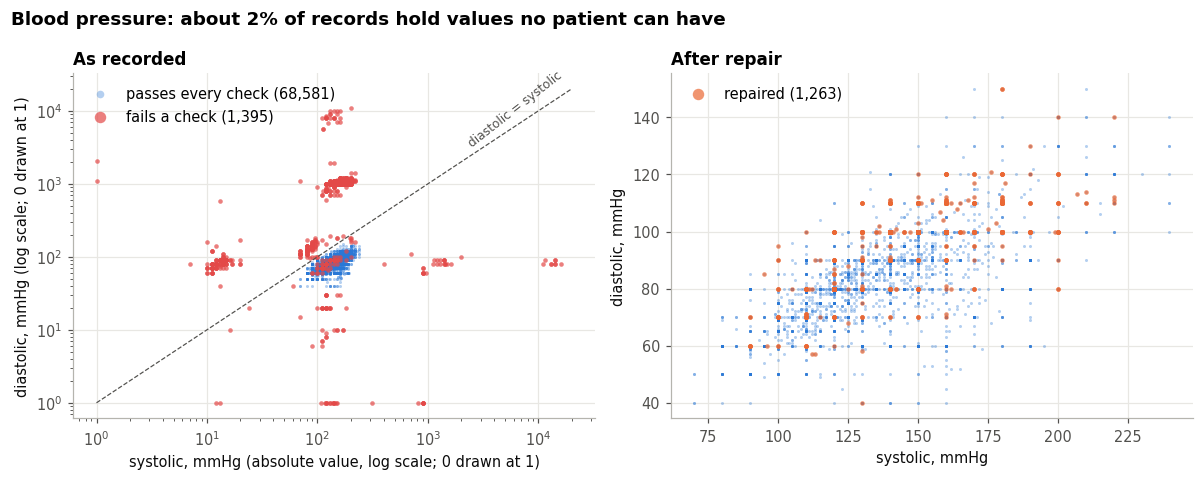

In [12]:
repaired, log = clean(raw, "repair")
bad = flags.any(axis=1)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
ax = axes[0]
for mask, colour, label, size in [(~bad, NO_CVD, "passes every check", 4), (bad, FLAG, "fails a check", 9)]:
    d = deduped[mask]
    ax.scatter(d["ap_hi"].abs().clip(lower=1), d["ap_lo"].abs().clip(lower=1), s=size,
               color=colour, alpha=0.35 if colour == NO_CVD else 0.7, linewidths=0, label=f"{label} ({mask.sum():,})")
ax.set(xscale="log", yscale="log", xlabel="systolic, mmHg (absolute value, log scale; 0 drawn at 1)",
       ylabel="diastolic, mmHg (log scale; 0 drawn at 1)", title="As recorded")
ax.plot([1, 2e4], [1, 2e4], color=MUTED, lw=0.8, ls="--")
ax.annotate("diastolic = systolic", (2.2e3, 3.3e3), color=MUTED, fontsize=8, rotation=38)
ax.legend(loc="upper left", markerscale=2.5)

ax = axes[1]
ax.scatter(repaired["ap_hi"], repaired["ap_lo"], s=4, color=NO_CVD, alpha=0.35, linewidths=0)
fixed = repaired["id"].isin(log.loc[log["rule"] != "unrecoverable", "id"])
ax.scatter(repaired.loc[fixed, "ap_hi"], repaired.loc[fixed, "ap_lo"], s=9, color=CVD, alpha=0.7,
           linewidths=0, label=f"repaired ({fixed.sum():,})")
ax.set(xlabel="systolic, mmHg", ylabel="diastolic, mmHg", title="After repair")
ax.legend(loc="upper left", markerscale=2.5)
fig.suptitle("Blood pressure: about 2% of records hold values no patient can have", x=0.01, ha="left",
             fontsize=12, fontweight="bold")
fig.tight_layout()
fig.savefig(FIGURES / "fig1_blood_pressure_cleaning.png")
plt.show()

The contradictory records are a smaller issue. Some records share every feature value but carry
different diagnoses:

In [13]:
features_only = deduped.drop(columns=["id", "cardio"])
groups = deduped[in_train].groupby(list(features_only.columns))["cardio"].nunique()
print(f"{(groups > 1).sum()} groups of training records identical in every feature but with different diagnoses")

12 groups of training records identical in every feature but with different diagnoses


These are kept. They are a reminder that the features do not determine the diagnosis: no model can
classify all of these records correctly.

### 4.2 Three cleaning strategies

Each strategy becomes its own training set (Q2):

In [14]:
summary = cleaning_summary(raw)
summary.style.format({"share kept": "{:.1%}", "records": "{:,}"})

,records,duplicates removed,records repaired,implausible removed,share kept,description
strategy,,,,,,
raw,"69,976",24,0,0,100.0%,"no cleaning: exact duplicates removed, every value kept as recorded"
drop,"68,581",24,0,1395,98.0%,remove every record with an implausible value
repair,"69,844",24,1263,132,99.8%,"fix blood pressures with a recognisable entry error, then remove what is still implausible"


`repair` corrects a blood pressure only when a single recognisable entry error explains it. Readings
typed into each other's fields are swapped first, on the values as recorded, and only when the
swapped pair is plausible. Each remaining reading may then be fixed by one of the other rules: sign,
unit or extra digits. A reading that would need two stacked guesses (a unit fix followed by a swap,
say) is not repaired, although the two readings of a record can each get one fix (16/10 becomes
160/100). Anything no rule recovers is removed, and so are implausible heights and weights,
whose errors show no pattern that would identify the true value. Every change is logged:

In [15]:
print(log.groupby(["field", "rule"]).size().rename("values").to_string())
log[log["rule"] != "unrecoverable"].groupby("rule").head(3).sort_values("rule")

field        rule         
ap_hi        cmHg             179
             extra digits      38
             sign               7
             unrecoverable      5
ap_hi/ap_lo  swapped          100
ap_lo        cmHg              15
             extra digits     950
             sign               1
             unrecoverable     54


,id,field,before,after,rule
100,815,ap_hi,14,140,cmHg
101,1294,ap_hi,14,140,cmHg
102,1360,ap_hi,11,110,cmHg
106,2654,ap_hi,902,90,extra digits
107,2845,ap_hi,906,90,extra digits
126,6822,ap_hi,909,90,extra digits
124,6525,ap_hi,-100,100,sign
153,22881,ap_hi,-115,115,sign
165,29313,ap_hi,-100,100,sign
0,681,ap_hi/ap_lo,120/150,150/120,swapped


The repairs are guesses, however well motivated. A recorded 906 may be 90 with a stray digit, or
96. This is why `repair` is compared against `drop`, which invents nothing, rather than silently
replacing it.

### 4.3 What cleaning changes

In [16]:
rows = []
for s in STRATEGIES:
    d, _ = clean(raw, s)
    d = d[d["id"].isin(train_ids)]
    rows.append({"strategy": s, "training records": len(d),
                 "corr(systolic, cardio)": d["ap_hi"].corr(d["cardio"]),
                 "corr(diastolic, cardio)": d["ap_lo"].corr(d["cardio"]),
                 "mean systolic": d["ap_hi"].mean(), "max systolic": d["ap_hi"].max()})
pd.DataFrame(rows).set_index("strategy")

,training records,"corr(systolic, cardio)","corr(diastolic, cardio)",mean systolic,max systolic
strategy,,,,,
raw,55980,0.053,0.066,128.837,16020
drop,54859,0.427,0.339,126.653,240
repair,55865,0.431,0.347,127.044,240


This is the most important number in the cleaning section. In the raw training data, systolic blood
pressure has almost no linear relationship with the diagnosis (r = 0.05). After either kind of
cleaning it is the strongest single predictor (r = 0.43). Fewer than 2% of records cause this. A
handful of values in the thousands dominate the variance and hide everything else. Anything linear,
such as a correlation or a logistic regression (even on standardised values), reads the raw data
wrongly. Tree models split on the order of values and should suffer far less. Section 9.1 tests
whether that holds.

## 5. Exploratory data analysis

From here on, the analysis uses the **training patients only**, cleaned with the `drop` strategy
(Section 9.1 compares it with the other two strategies). The test patients stay unseen until
Section 8.

The modelling table is built by the functions below. They convert units, add the derived features
explained in Section 6, and divide the patients by the fixed train/test ids of Section 2.

In [17]:
def prepare(df: pd.DataFrame) -> pd.DataFrame:
    """Readable units and codes: age in years, sex as male = 1.

    The documentation calls gender 'a categorical code'. Code 2 is male: its mean height is 8.5 cm
    above code 1 (169.9 vs 161.4 cm), the usual adult sex difference.
    """
    out = df.copy()
    out["age_years"] = out["age"] / 365.25
    out["male"] = (out["gender"] == 2).astype(int)
    return out.drop(columns=["age", "gender"])


def bp_stage(systolic: pd.Series, diastolic: pd.Series) -> pd.Series:
    """ACC/AHA 2017 category: the higher of the systolic and diastolic categories."""
    sys_stage = np.select([systolic >= 140, systolic >= 130, systolic >= 120], [3, 2, 1], 0)
    dia_stage = np.select([diastolic >= 90, diastolic >= 80], [3, 2], 0)
    return pd.Series(np.maximum(sys_stage, dia_stage), index=systolic.index)


def add_features(df: pd.DataFrame) -> pd.DataFrame:
    """Clinically standard quantities derived from the recorded values."""
    out = df.copy()
    out["bmi"] = bmi(out)
    out["pulse_pressure"] = out["ap_hi"] - out["ap_lo"]
    out["mean_arterial_pressure"] = (out["ap_hi"] + 2 * out["ap_lo"]) / 3
    out["bp_stage"] = bp_stage(out["ap_hi"], out["ap_lo"])
    return out


def dataset(strategy: str = "drop", path: Path | str = DATA) -> pd.DataFrame:
    """Load, clean, prepare and derive features: the table every model is trained on."""
    cleaned, _ = clean(load(path), strategy)
    return add_features(prepare(cleaned))


def train_test(strategy: str = "drop", path: Path | str = DATA) -> tuple[pd.DataFrame, pd.DataFrame]:
    """The modelling table for one cleaning strategy, divided by the fixed train/test patient ids."""
    train_ids, test_ids = split_ids(load(path))
    data = dataset(strategy, path)
    return (data[data["id"].isin(train_ids)].reset_index(drop=True),
            data[data["id"].isin(test_ids)].reset_index(drop=True))

In [18]:
train, test = train_test("drop")
print(f"training patients: {len(train):,}   test patients: {len(test):,}")
print(f"share with CVD in training: {train['cardio'].mean():.1%}")
print(f"age {train['age_years'].min():.0f}-{train['age_years'].max():.0f} years, "
      f"median {train['age_years'].median():.0f}; {train['male'].mean():.0%} men")

training patients: 54,859   test patients: 13,722
share with CVD in training: 49.5%
age 30-65 years, median 54; 35% men


### 5.1 Disease rate by risk factor

The most direct way to see what the data holds is the share of patients with CVD at each level of
each factor. The dashed line marks the overall rate.

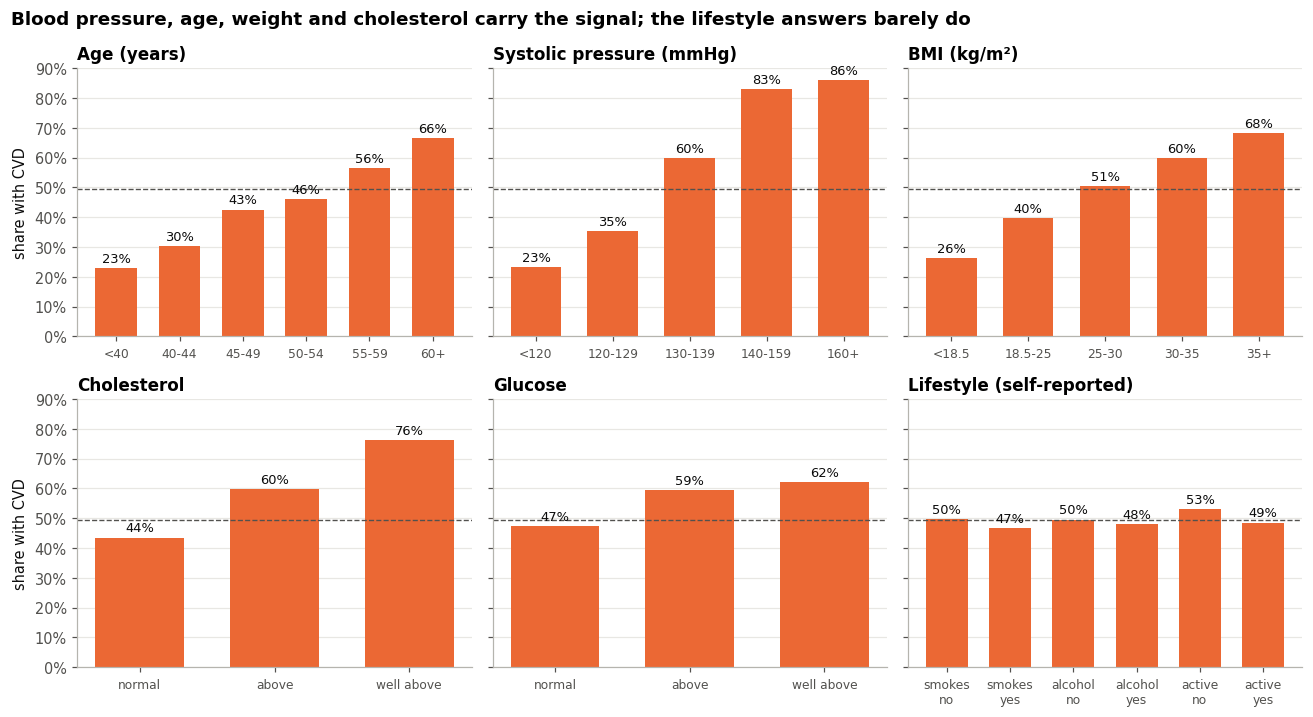

In [19]:
def band(series, edges, labels):
    return pd.cut(series, edges, labels=labels, right=False)

LEVELS = ["normal", "above", "well above"]
panels = [
    ("Age (years)", band(train["age_years"], [0, 40, 45, 50, 55, 60, 70],
                        ["<40", "40-44", "45-49", "50-54", "55-59", "60+"])),
    ("Systolic pressure (mmHg)", band(train["ap_hi"], [0, 120, 130, 140, 160, 400],
                                      ["<120", "120-129", "130-139", "140-159", "160+"])),
    ("BMI (kg/m²)", band(train["bmi"], [0, 18.5, 25, 30, 35, 100],
                         ["<18.5", "18.5-25", "25-30", "30-35", "35+"])),
    ("Cholesterol", pd.Categorical(train["cholesterol"].map(dict(enumerate(LEVELS, 1))), LEVELS)),
    ("Glucose", pd.Categorical(train["gluc"].map(dict(enumerate(LEVELS, 1))), LEVELS)),
]
lifestyle = [(f"{name}\n{answer}", train.loc[train[col] == value, "cardio"])
             for col, name in [("smoke", "smokes"), ("alco", "alcohol"), ("active", "active")]
             for value, answer in [(0, "no"), (1, "yes")]]
overall = train["cardio"].mean()

fig, axes = plt.subplots(2, 3, figsize=(12, 6.6), sharey=True)
for ax, panel in zip(axes.flat, panels + [("Lifestyle (self-reported)", None)]):
    title, groups = panel
    if groups is None:
        labels = [name for name, _ in lifestyle]
        rates = [s.mean() for _, s in lifestyle]
    else:
        g = train.groupby(pd.Series(groups, index=train.index), observed=False)["cardio"].mean()
        labels, rates = list(g.index), list(g)
    x = np.arange(len(labels))
    ax.bar(x, rates, width=0.66, color=CVD)
    for xi, r in zip(x, rates):
        ax.text(xi, r + 0.02, f"{r:.0%}", ha="center", fontsize=8.5, color=INK)
    ax.axhline(overall, color=MUTED, lw=0.9, ls="--")
    ax.set_xticks(x, labels, fontsize=8)
    ax.set(title=title, ylim=(0, 0.9))
    ax.grid(axis="x", visible=False)
    ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
for ax in axes[:, 0]:
    ax.set_ylabel("share with CVD")
fig.suptitle("Blood pressure, age, weight and cholesterol carry the signal; the lifestyle answers barely do",
             x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout()
fig.savefig(FIGURES / "fig2_disease_rate_by_factor.png")
plt.show()

Four factors carry most of the signal, and each rises steadily with no reversal:

- **Systolic blood pressure** is the strongest. The disease rate climbs from about a quarter of
  patients below 120 mmHg to most patients at 160 mmHg and above.
- **Age.** The rate roughly triples between patients under 40 and those over 60.
- **Weight.** The rate rises across the BMI categories, from about a quarter of underweight patients
  to about two thirds of those with a BMI of 35 or more.
- **Cholesterol** is the strongest of the lab results. Three quarters of patients with "well above
  normal" cholesterol have CVD. Glucose follows the same pattern, but more weakly.

The three lifestyle answers barely move the rate, and two point the "wrong" way: smokers and drinkers
have slightly *lower* disease rates than other patients. Only physical activity has the expected
protective sign. Section 5.2 checks whether this survives a fairer comparison.

### 5.2 The smoking paradox

Smoking is an established cause of cardiovascular disease, so a lower rate among smokers needs an
explanation. The first suspect is a confounder. Smokers in this data are mostly men (22% of men
smoke, against 2% of women), and risk rises with age, so the comparison is redone among men, age
group by age group. The gap is then
averaged over the age groups (weighted by their size), with a bootstrap confidence interval:

share who smoke: {'women': '1.8%', 'men': '21.9%'}


men, smokers minus the others, same age: -3.1 points (95% CI -4.9 to -1.5)


men, drinkers minus the others, same age: -2.0 points (95% CI -4.3 to +0.3)
men who drink: 31% of smokers, 5% of non-smokers


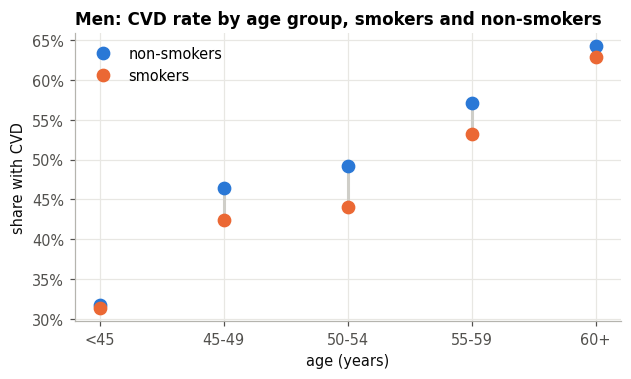

In [20]:
print("share who smoke:", train.groupby("male")["smoke"].mean().rename({0: "women", 1: "men"})
      .map("{:.1%}".format).to_dict())

men = train[train["male"] == 1].copy()
men["age band"] = band(men["age_years"], [0, 45, 50, 55, 60, 70], ["<45", "45-49", "50-54", "55-59", "60+"])
by_age = men.groupby(["age band", "smoke"], observed=True)["cardio"].agg(["mean", "size"]).unstack()
rate = by_age["mean"].rename(columns={0: "non-smokers", 1: "smokers"})


def age_standardised_gap(d, col):
    """CVD rate of the 'yes' group minus the 'no' group within each age band, averaged over the bands
    with the band sizes as weights."""
    r = d.groupby(["age band", col], observed=True)["cardio"].mean().unstack()
    w = d.groupby("age band", observed=True).size()
    return float(((r[1] - r[0]) * w).sum() / w.sum())


rng = np.random.default_rng(SEED)
for col, label in [("smoke", "smokers"), ("alco", "drinkers")]:
    gap = age_standardised_gap(men, col)
    boot = [age_standardised_gap(men.iloc[rng.integers(0, len(men), len(men))], col) for _ in range(1000)]
    lo, hi = np.percentile(boot, [2.5, 97.5])
    print(f"men, {label} minus the others, same age: {gap * 100:+.1f} points (95% CI {lo * 100:+.1f} to {hi * 100:+.1f})")
print(f"men who drink: {men.loc[men['smoke'] == 1, 'alco'].mean():.0%} of smokers, "
      f"{men.loc[men['smoke'] == 0, 'alco'].mean():.0%} of non-smokers")

fig, ax = plt.subplots(figsize=(6.4, 3.4))
x = np.arange(len(rate))
ax.vlines(x, rate.min(axis=1), rate.max(axis=1), color="#cfcec8", lw=2, zorder=1)
for col, colour in [("non-smokers", NO_CVD), ("smokers", CVD)]:
    ax.plot(x, rate[col], "o", color=colour, ms=8, label=col, zorder=2)
ax.set_xticks(x, rate.index)
ax.set(xlabel="age (years)", ylabel="share with CVD", title="Men: CVD rate by age group, smokers and non-smokers")
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1, decimals=0))
ax.legend(loc="upper left")
fig.savefig(FIGURES / "fig3_smoking_paradox.png")
plt.show()
by_age.style.format("{:.1%}", subset="mean").format("{:,}", subset="size")

For smoking the paradox survives. Among men (women hardly smoke here), smokers have the same or a
lower disease rate than non-smokers in every age group. The gap is small and uncertain in the
youngest and oldest groups, but compared age for age, smokers have 3.1 points less CVD (95% CI 1.5
to 4.9 points less), and the confidence interval excludes zero. For alcohol the evidence is
inconclusive: the age-standardised gap is −2.0 points (95% CI −4.3 to +0.3), and its interval
includes zero. Smokers also drink far more than non-smokers (31% against 5%), which this simple
comparison does not separate.

A plausible explanation lies in how the data was collected rather than in biology, though the data
cannot test it: it has no "former smoker" answer. The diagnosis and the answers were recorded **at
the same examination**. A patient who already has heart disease may have been told to quit, and then
answers "no" to smoking, which moves diseased former smokers into the non-smoker group. This "sick
quitter" effect was first described for alcohol [8].

Two consequences for the rest of the study follow from how the data was recorded, whatever the
explanation for smoking:

1. The task is **detection of an existing disease**, not prediction of a future one. A model trained
   here can say "this profile looks like the profiles of patients who have CVD". It cannot say "this
   person will develop CVD".
2. Feature effects learned from this data are **associations, not causes**. A model that gives
   smoking a negative weight is describing the data correctly, but no one should be told that smoking
   protects the heart. Section 8 returns to this when the model is explained.

### 5.3 Correlations between features

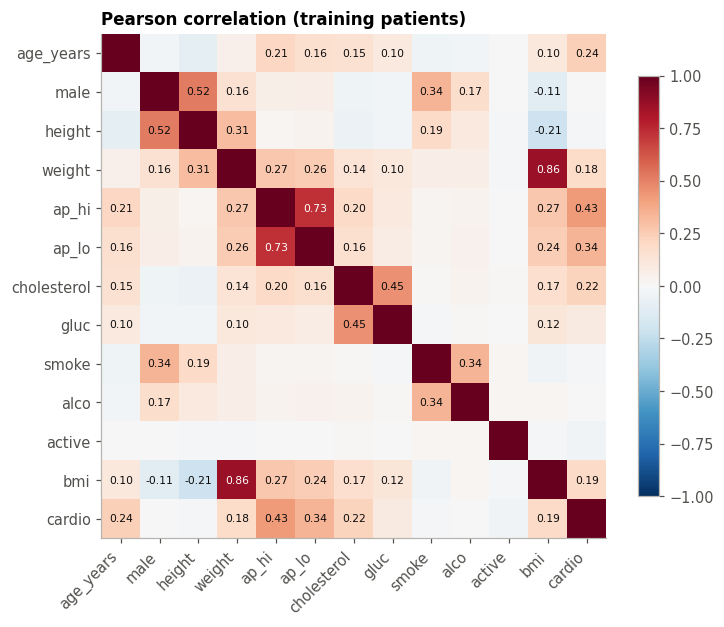

,correlation with CVD
ap_hi,0.427
ap_lo,0.339
age_years,0.240
cholesterol,0.222
bmi,0.193
weight,0.183
gluc,0.093
male,0.007
alco,-0.006
height,-0.012


In [21]:
cols = BASE_FEATURES + ["bmi", "cardio"]
corr = train[cols].corr()

fig, ax = plt.subplots(figsize=(7.4, 6.2))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(cols)), cols, rotation=45, ha="right")
ax.set_yticks(range(len(cols)), cols)
for i in range(len(cols)):
    for j in range(len(cols)):
        v = corr.iloc[i, j]
        if i != j and abs(v) >= 0.1:
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7,
                    color="white" if abs(v) > 0.6 else INK)
ax.grid(False)
ax.set_title("Pearson correlation (training patients)")
fig.colorbar(im, ax=ax, shrink=0.8)
fig.savefig(FIGURES / "fig4_correlations.png")
plt.show()
corr["cardio"].drop("cardio").sort_values(ascending=False).rename("correlation with CVD").to_frame()

The last column restates Section 5.1 as single numbers. Systolic pressure, diastolic pressure, age,
cholesterol and BMI lead, while sex and the lifestyle answers are close to zero. Among the features
themselves, the two blood pressures are strongly correlated (0.73), and so are weight and BMI (0.86);
sex and height moderately (0.52), and cholesterol and glucose too (0.45). For tree models this hardly
matters. For logistic regression it means individual coefficients must be read with care, since
correlated features share their effect.

### 5.4 What the exploration implies for modelling

- The strongest relationships are **monotonic**: the risk rises steadily with blood pressure, age,
  BMI and cholesterol. A linear model on suitable features should capture most of the signal, so
  flexible models have limited room to improve on it. This is the expectation Q1 will test.
- **No class imbalance**: 49.5% of training patients have CVD. Oversampling methods such as SMOTE
  have nothing to fix here. In Section 9 they appear only as one of the mistakes the leakage
  experiments reproduce.
- The lifestyle answers are weak, and for smoking the association may be distorted by reverse
  causation, which the data cannot test. They are kept, because a model should use what the
  examination records, but nothing causal is read into them.

## 6. Feature engineering

Four clinically standard quantities are added to the eleven recorded ones:

| Feature | Definition | Why |
|---|---|---|
| `bmi` | weight / height² (kg/m²) | the usual measure of excess weight; height and weight alone do not express it |
| `pulse_pressure` | systolic − diastolic | a marker of arterial stiffness |
| `mean_arterial_pressure` | (systolic + 2 × diastolic) / 3 | average pressure over the cardiac cycle |
| `bp_stage` | ACC/AHA 2017: 0 normal, 1 elevated, 2 stage 1, 3 stage 2 | the categories clinicians act on |

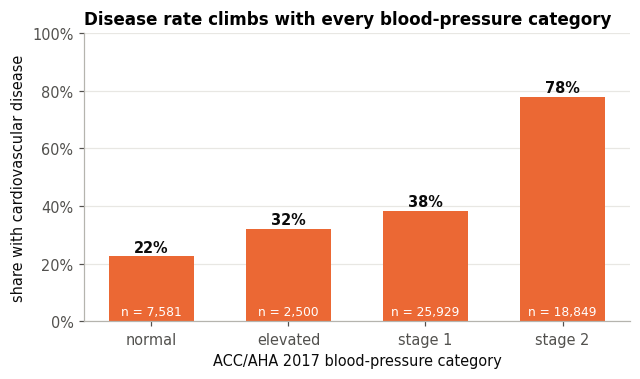

most common reading: 120/80 mmHg, 34% of training patients
readings that are multiples of 10: 97% of systolic, 97% of diastolic


In [22]:
rate = train.groupby("bp_stage")["cardio"].agg(["mean", "size"])

fig, ax = plt.subplots(figsize=(6.4, 3.4))
ax.bar(range(4), rate["mean"], width=0.62, color=CVD)
for i, (m, n) in enumerate(zip(rate["mean"], rate["size"])):
    ax.text(i, m + 0.015, f"{m:.0%}", ha="center", color=INK, fontsize=9.5, fontweight="bold")
    ax.text(i, 0.02, f"n = {n:,}", ha="center", color="white", fontsize=8)
ax.set_xticks(range(4), BP_STAGE_NAMES)
ax.set(ylim=(0, 1), ylabel="share with cardiovascular disease", xlabel="ACC/AHA 2017 blood-pressure category",
       title="Disease rate climbs with every blood-pressure category")
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.grid(axis="x", visible=False)
fig.savefig(FIGURES / "fig5_disease_by_bp_stage.png")
plt.show()
top = train.groupby(["ap_hi", "ap_lo"]).size().sort_values(ascending=False)
print(f"most common reading: {top.index[0][0]}/{top.index[0][1]} mmHg, {top.iloc[0] / len(train):.0%} of training patients")
print(f"readings that are multiples of 10: {(train['ap_hi'] % 10 == 0).mean():.0%} of systolic, "
      f"{(train['ap_lo'] % 10 == 0).mean():.0%} of diastolic")

The large stage 1 group follows from the guideline, not from an error. The most common reading,
120/80 (a third of the training patients), is stage 1 because a diastolic pressure of 80 mmHg starts
stage 1 in the 2017 guideline. Almost every reading is a multiple of 10, so a few values decide most
patients' stage.

The derived category summarises both pressures in the terms clinicians act on, and the disease rate
rises steadily across it: from about one patient in five at normal pressure to most patients at
stage 2.

Three points about these features:

- **They are fixed formulas, not learned transformations.** Like the cleaning rules, they cannot
  leak test information.
- **They overlap with the recorded values on purpose.** BMI is a function of height and weight, and
  the three pressure features are functions of the two readings. Tree models can gain from having
  the combination precomputed, since a split on BMI replaces many splits on height and weight. For
  logistic regression the overlap is handled by regularisation. Section 7 checks whether the derived
  features help at all, by training the same models with and without them.
- **The stage builds the guideline's thresholds into the data.** It steps at 120, 130 and 140 mmHg
  systolic, so any model can use those thresholds directly. Section 8.4 keeps this in mind when
  reading the shape of the model.

## 7. Models

### 7.1 What is compared

Every candidate is evaluated with 5-fold cross-validation on the training patients, using the same
five folds. All models are implemented with scikit-learn [12]. The test patients are not touched in
this section.

| Candidate | Type | What it uses | Settings searched |
|---|---|---|---|
| Rule: systolic ≥ 130 mmHg | clinical baseline | one reading, guideline threshold | none |
| Systolic pressure alone | clinical baseline | one reading; cut-off chosen on the training folds | none |
| Framingham (published) | clinical baseline | age, sex, BMI, systolic pressure, smoking, diabetes | none: the 2008 equations as published |
| Framingham form (refit) | logistic regression | the same terms, one equation per sex | 1 setting: coefficients refitted on these patients |
| Logistic regression | linear model | all 15 features, standardised | 4 settings: regularisation strength C |
| Random forest | tree ensemble (200 trees) | all 15 features | 9 settings: leaf size, features per split |
| Gradient boosting | tree ensemble (histogram GBDT, early stopping) | all 15 features | 27 settings: learning rate, tree size, leaf size |
| Neural network (MLP) | multilayer perceptron | all 15 features, standardised | 16 settings: layer sizes, weight decay |

The search grids differ in size: the more settings a model has that matter, the more were tried.
Section 7.2 checks how much the grids matter by looking at how flat each search is.

Some notes on the baselines:

- **The Framingham score answers a different question.** It was built to predict a *first*
  cardiovascular event over the next ten years in people free of CVD, while this dataset records
  existing disease. The dataset also has no field for blood-pressure treatment, so the equation for
  untreated patients is used, and no diabetes field, so glucose "well above normal" stands in for
  diabetes. Using its risk to rank these patients is therefore a reference point, not a fair contest.
  The refitted version keeps Framingham's terms but learns the weights from these patients. It shows
  how much of any gap comes from the terms and how much from the weights.
- **Two baselines need a cut-off.** Systolic pressure alone and the published Framingham risk are
  continuous scores, so the cut-off that classifies the four training folds most accurately is
  applied to the fifth. Their AUC needs no cut-off.

**Selection rule, fixed in advance.** The final model is the *simplest* machine-learning model whose
mean cross-validated AUC is within one standard error of the best one. The order of simplicity: the
Framingham form and logistic regression first (a few coefficients that can be read directly), then
the tree ensembles from smaller to larger (gradient boosting builds small trees, at most 31 leaves
each; random forest grows 200 deep ones), and the neural network last, usually considered the
hardest to inspect. A difference smaller than the fold-to-fold noise is not evidence, so it should
not buy complexity.

### 7.2 Cross-validated comparison

The baselines and models of Section 7.1, and the cross-validated comparison that scores them all on
the same five folds:

In [23]:
# Framingham general cardiovascular risk, office-based model (BMI instead of cholesterol), for
# patients not treated for hypertension (D'Agostino et al., Circulation 2008):
#     10-year risk = 1 - s0 ** exp(sum(coefficient * term) - mean)
FRAMINGHAM = {
    0: {"ln_age": 2.72107, "ln_bmi": 0.51125, "ln_sbp": 2.81291, "smoke": 0.61868, "diabetes": 0.77763,
        "s0": 0.94833, "mean": 26.0145},   # women
    1: {"ln_age": 3.11296, "ln_bmi": 0.79277, "ln_sbp": 1.85508, "smoke": 0.70953, "diabetes": 0.53160,
        "s0": 0.88431, "mean": 23.9388},   # men
}
SBP_RULE = 130  # mmHg: stage 1 hypertension (ACC/AHA 2017)


def diabetes_proxy(df: pd.DataFrame) -> pd.Series:
    """The dataset has no diabetes field; glucose 'well above normal' is the closest stand-in."""
    return (df["gluc"] == 3).astype(int)


def framingham_terms(df: pd.DataFrame) -> np.ndarray:
    """ln age, ln BMI, ln systolic pressure, smoking and diabetes: the Framingham office model's inputs."""
    return np.column_stack([np.log(df["age_years"]), np.log(df["bmi"]), np.log(df["ap_hi"]),
                            df["smoke"], diabetes_proxy(df)])


def framingham_risk(df: pd.DataFrame) -> pd.Series:
    """Published Framingham 10-year CVD risk, as a clinician would compute it, with nothing refitted."""
    terms = framingham_terms(df)
    risk = np.full(len(df), np.nan)
    for male, c in FRAMINGHAM.items():
        rows = df["male"].to_numpy() == male
        beta = np.array([c["ln_age"], c["ln_bmi"], c["ln_sbp"], c["smoke"], c["diabetes"]])
        risk[rows] = 1 - c["s0"] ** np.exp(terms[rows] @ beta - c["mean"])
    return pd.Series(risk, index=df.index)


def framingham_design(df: pd.DataFrame) -> np.ndarray:
    """Framingham's terms once for women and once for men, plus a sex indicator, so that a logistic
    regression refits the published model's two equations on this population."""
    male = df["male"].to_numpy()[:, None]
    terms = framingham_terms(df)
    return np.column_stack([terms * (1 - male), terms * male, male])

In [24]:
N_JOBS = int(os.environ.get("CARDIO_JOBS", "4"))
CV_FOLDS = 5
# Simplest first: when several models are statistically tied, the earliest in this order is chosen.
# Fixed before any result: the two linear models (a few coefficients that can be read directly), then
# the tree ensembles from smaller to larger (gradient boosting builds small trees, at most 31 leaves
# each; random forest grows 200 deep ones), then the neural network, the hardest to inspect.
SIMPLICITY = ["Framingham form (refit)", "Logistic regression", "Gradient boosting", "Random forest",
              "Neural network (MLP)"]


def cv_splitter(seed: int = SEED):
    from sklearn.model_selection import StratifiedKFold
    return StratifiedKFold(CV_FOLDS, shuffle=True, random_state=seed)


def model_specs() -> dict[str, tuple]:
    """Each model with the hyperparameter grid that cross-validation searches."""
    from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
    from sklearn.linear_model import LogisticRegression
    from sklearn.neural_network import MLPClassifier
    from sklearn.pipeline import Pipeline
    from sklearn.preprocessing import FunctionTransformer, StandardScaler

    def scaled(name, model):
        return Pipeline([("scale", StandardScaler()), (name, model)])

    return {
        "Framingham form (refit)": (
            Pipeline([("terms", FunctionTransformer(framingham_design)), ("scale", StandardScaler()),
                      ("lr", LogisticRegression(max_iter=5000))]),
            {"lr__C": [1.0]}),
        "Logistic regression": (
            scaled("lr", LogisticRegression(max_iter=5000)),
            {"lr__C": [0.01, 0.1, 1.0, 10.0]}),
        "Random forest": (
            RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=1),
            {"min_samples_leaf": [10, 30, 100], "max_features": [2, "sqrt", 0.5]}),
        "Gradient boosting": (
            # early stopping on 10% of the training data (sklearn's default above 10,000 rows) ends
            # the boosting long before max_iter at the larger learning rates
            HistGradientBoostingClassifier(max_iter=1000, early_stopping=True, random_state=SEED),
            {"learning_rate": [0.01, 0.03, 0.1], "max_leaf_nodes": [7, 15, 31],
             "min_samples_leaf": [20, 50, 200]}),
        "Neural network (MLP)": (
            scaled("mlp", MLPClassifier(early_stopping=True, max_iter=300, random_state=SEED)),
            {"mlp__hidden_layer_sizes": [(32,), (64, 32), (128, 64), (256, 128)],
             "mlp__alpha": [1e-4, 1e-2, 1e-1, 1.0]}),
    }


def classification_metrics(y, score, threshold: float) -> dict:
    """AUC from the score; accuracy, sensitivity and specificity from score >= threshold."""
    from sklearn.metrics import roc_auc_score

    y = np.asarray(y)
    pred = np.asarray(score) >= threshold
    return {"auc": roc_auc_score(y, score), "accuracy": (pred == y).mean(),
            "sensitivity": pred[y == 1].mean(), "specificity": (~pred[y == 0]).mean()}


def accuracy_threshold(y, score) -> float:
    """The cut-off on a score that classifies the given (training) patients most accurately."""
    y, score = np.asarray(y), np.asarray(score)
    candidates = np.unique(np.quantile(score, np.linspace(0.01, 0.99, 197)))
    return candidates[np.argmax([((score >= t) == y).mean() for t in candidates])]


def compare_models(train: pd.DataFrame, features: list[str] = FEATURES, specs: dict | None = None,
                   n_jobs: int = N_JOBS) -> tuple[pd.DataFrame, dict]:
    """Cross-validated comparison of the clinical baselines and the machine-learning models.

    Everything is scored on the same five validation folds of the training patients. The baselines
    fit nothing; where a baseline needs a cut-off (systolic pressure alone, published Framingham risk),
    it is chosen on the other four folds. Each model's grid is searched by AUC, and its row reports
    the best setting. `auc_sd` is the sample standard deviation over the five folds for every row.
    Returns the table and the fitted searches (refitted on all training patients).
    """
    from sklearn.metrics import make_scorer, recall_score
    from sklearn.model_selection import GridSearchCV

    X, y = train[features], train[TARGET]
    cv = cv_splitter()
    rows = []
    baselines = [
        (f"Rule: systolic ≥ {SBP_RULE} mmHg", (train["ap_hi"] >= SBP_RULE).astype(float), 0.5),
        ("Systolic pressure alone", train["ap_hi"].astype(float), None),
        ("Framingham (published)", framingham_risk(train), None),
    ]
    for name, score, fixed in baselines:
        folds = []
        for tr, va in cv.split(X, y):
            cut = fixed if fixed is not None else accuracy_threshold(y.iloc[tr], score.iloc[tr])
            folds.append(classification_metrics(y.iloc[va], score.iloc[va], cut))
        f = pd.DataFrame(folds)
        rows.append({"model": name, "kind": "clinical baseline", "auc": f["auc"].mean(), "auc_sd": f["auc"].std(),
                     **f[["accuracy", "sensitivity", "specificity"]].mean().to_dict(),
                     "best setting": "-" if fixed is not None else "cut-off chosen on training folds",
                     "fit seconds": 0.0})

    scoring = {"auc": "roc_auc", "accuracy": "accuracy", "sensitivity": make_scorer(recall_score),
               "specificity": make_scorer(recall_score, pos_label=0)}
    searches = {}
    for name, (estimator, grid) in (specs if specs is not None else model_specs()).items():
        search = GridSearchCV(estimator, grid, scoring=scoring, refit="auc", cv=cv, n_jobs=n_jobs)
        search.fit(X, y)
        r, i = search.cv_results_, search.best_index_
        fold_aucs = [r[f"split{k}_test_auc"][i] for k in range(CV_FOLDS)]
        rows.append({"model": name, "kind": "machine learning", "auc": r["mean_test_auc"][i],
                     "auc_sd": float(np.std(fold_aucs, ddof=1)),
                     **{m: r[f"mean_test_{m}"][i] for m in ("accuracy", "sensitivity", "specificity")},
                     "best setting": ", ".join(f"{k.split('__')[-1]}={v}" for k, v in search.best_params_.items()),
                     "fit seconds": r["mean_fit_time"][i]})
        searches[name] = search
    return pd.DataFrame(rows).set_index("model"), searches


def choose_model(table: pd.DataFrame) -> str:
    """The simplest machine-learning model whose CV AUC is within one standard error of the best.

    Differences smaller than the fold-to-fold noise are not evidence that one model is better, so they
    should not buy complexity (the 'one-standard-error rule').
    """
    ml = table[table["kind"] == "machine learning"]
    best = ml["auc"].idxmax()
    margin = ml.loc[best, "auc_sd"] / math.sqrt(CV_FOLDS)
    tied = ml.index[ml["auc"] >= ml.loc[best, "auc"] - margin]
    return min(tied, key=SIMPLICITY.index)


def feature_set_comparison(train: pd.DataFrame, searches: dict, names: list[str],
                           n_jobs: int = N_JOBS) -> pd.DataFrame:
    """CV AUC of the chosen settings with the recorded features only, and with the derived ones too."""
    from sklearn.base import clone
    from sklearn.model_selection import cross_val_score

    rows = []
    for name in names:
        for label, cols in (("recorded only", BASE_FEATURES), ("recorded + derived", FEATURES)):
            s = cross_val_score(clone(searches[name].best_estimator_), train[cols], train[TARGET],
                                cv=cv_splitter(), scoring="roc_auc", n_jobs=n_jobs)
            rows.append({"model": name, "features": label, "auc": s.mean(), "auc_sd": s.std(ddof=1)})
    return pd.DataFrame(rows).pivot(index="model", columns="features", values="auc")


def learning_curve_auc(train: pd.DataFrame, estimators: dict,
                       sizes: tuple = (0.01, 0.02, 0.05, 0.1, 0.25, 0.5, 1.0),
                       n_jobs: int = N_JOBS) -> pd.DataFrame:
    """Validation AUC as the number of training patients grows (sizes are shares of a training fold):
    does the model run out of data, or of information in the features?"""
    from sklearn.base import clone
    from sklearn.model_selection import learning_curve

    rows = []
    for name, est in estimators.items():
        n, _, val = learning_curve(clone(est), train[FEATURES], train[TARGET], train_sizes=list(sizes),
                                   cv=cv_splitter(), scoring="roc_auc", n_jobs=n_jobs, shuffle=True,
                                   random_state=SEED)
        rows += [{"model": name, "patients": k, "auc": v.mean(), "auc_sd": v.std(ddof=1)} for k, v in zip(n, val)]
    return pd.DataFrame(rows)

In [25]:
import time

t0 = time.time()
comparison, searches = compare_models(train)
print(f"{len(searches)} grid searches and 3 baselines, {CV_FOLDS}-fold CV: {time.time() - t0:.0f} s")
(comparison.sort_values("auc", ascending=False)
 .style.format({"auc": "{:.4f}", "auc_sd": "{:.4f}", "accuracy": "{:.1%}", "sensitivity": "{:.1%}",
                "specificity": "{:.1%}", "fit seconds": "{:.1f}"}))

5 grid searches and 3 baselines, 5-fold CV: 309 s


,kind,auc,auc_sd,accuracy,sensitivity,specificity,best setting,fit seconds
model,,,,,,,,
Gradient boosting,machine learning,0.8005,0.0029,73.5%,69.1%,77.8%,"learning_rate=0.01, max_leaf_nodes=15, min_samples_leaf=50",3.1
Neural network (MLP),machine learning,0.7996,0.0027,73.4%,68.1%,78.6%,"alpha=0.1, hidden_layer_sizes=(64, 32)",4.0
Random forest,machine learning,0.7992,0.0031,73.3%,68.4%,78.2%,"max_features=sqrt, min_samples_leaf=30",7.0
Logistic regression,machine learning,0.7902,0.0029,72.7%,67.1%,78.3%,C=0.1,0.1
Framingham form (refit),machine learning,0.7798,0.0038,71.8%,67.1%,76.5%,C=1.0,0.2
Systolic pressure alone,clinical baseline,0.7506,0.0035,71.3%,61.8%,80.7%,cut-off chosen on training folds,0.0
Rule: systolic ≥ 130 mmHg,clinical baseline,0.7121,0.0037,71.3%,61.8%,80.7%,-,0.0
Framingham (published),clinical baseline,0.6962,0.0031,65.2%,75.4%,55.2%,cut-off chosen on training folds,0.0


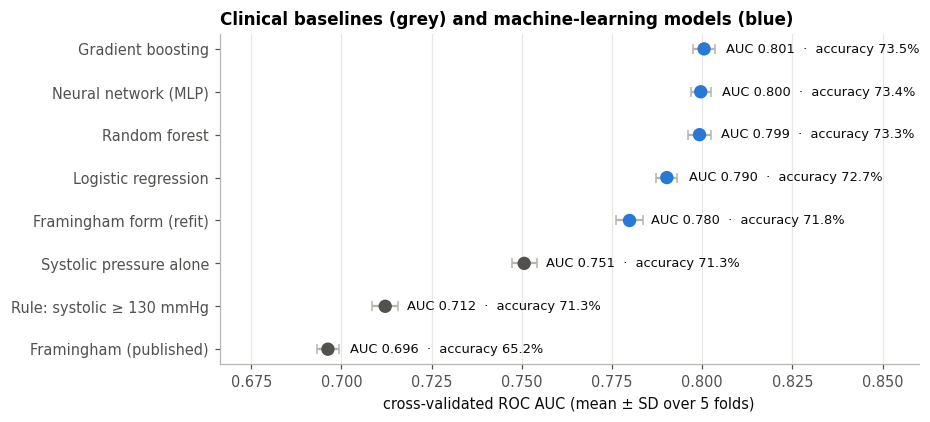

In [26]:
order = comparison.sort_values("auc")
fig, ax = plt.subplots(figsize=(8.2, 3.9))
y = np.arange(len(order))
colours = [NO_CVD if k == "machine learning" else MUTED for k in order["kind"]]
ax.errorbar(order["auc"], y, xerr=order["auc_sd"], fmt="none", ecolor="#b5b4ae", elinewidth=1.5, capsize=3)
ax.scatter(order["auc"], y, s=60, color=colours, zorder=3)
for yi, (auc, acc) in enumerate(zip(order["auc"], order["accuracy"])):
    ax.text(auc + 0.006, yi, f"AUC {auc:.3f}  ·  accuracy {acc:.1%}", va="center", fontsize=8.5, color=INK)
ax.set_yticks(y, order.index)
ax.set(xlabel="cross-validated ROC AUC (mean ± SD over 5 folds)", xlim=(order["auc"].min() - 0.03, 0.86),
       title="Clinical baselines (grey) and machine-learning models (blue)")
ax.grid(axis="y", visible=False)
fig.savefig(FIGURES / "fig6_model_comparison.png")
plt.show()

**Every machine-learning model beats every clinical baseline, but the margins over the best baseline
are small.**

- **Best model.** Gradient boosting reaches a cross-validated AUC of 0.800 and an accuracy of 73.5%.
  The guideline rule (systolic ≥ 130 mmHg) is right for 71.3% of patients. Out of every 1,000
  patients, the best model classifies about 22 more correctly than one blood-pressure reading.
- **The flexible models are close.** Gradient boosting (0.8005), the neural network (0.7996) and
  random forest (0.7992) lie within 0.0013 AUC of each other, less than the fold-to-fold standard
  deviation (about 0.003). Logistic regression is 0.010 behind, so the curves and interactions that
  trees and networks can represent are worth a little, but only a little.
- **The guideline's threshold is also the most accurate cut-off.** When systolic pressure alone is
  given the cut-off that classifies the training folds most accurately, it classifies exactly like
  the guideline's 130 mmHg: its cross-validated accuracy, sensitivity and specificity are identical
  to the rule's, and on all training patients the search returns 130 mmHg itself (Section 8.1).
  (Almost all readings are multiples of 10, so the search chooses among a handful of values; this is
  a consistency check, not a discovery.) The AUC differs only because the rule turns the reading
  into a yes/no answer.
- **The published Framingham score ranks these patients worse than systolic pressure alone** (AUC
  0.696 vs 0.751). Refitting the same five terms on these patients raises it to 0.780: the terms are
  informative, but the published weights do not transfer to this population and question (existing
  disease here, a first event within ten years in Framingham). Section 8.1 shows where they go
  wrong.

How flat is each search? If the best setting is barely better than its neighbours, nothing much
hinges on the grid:

In [27]:
flat = []
for name, s in searches.items():
    scores = np.sort(s.cv_results_["mean_test_auc"])[::-1]
    flat.append({"model": name, "settings tried": len(scores), "best": scores[0],
                 "second best": scores[1] if len(scores) > 1 else np.nan,
                 "median setting": float(np.median(scores)), "worst": scores[-1],
                 "best setting": comparison.loc[name, "best setting"]})
(pd.DataFrame(flat).set_index("model")
 .style.format("{:.4f}", subset=["best", "second best", "median setting", "worst"], na_rep="-"))

,settings tried,best,second best,median setting,worst,best setting
model,,,,,,
Framingham form (refit),1,0.7798,-,0.7798,0.7798,C=1.0
Logistic regression,4,0.7902,0.7902,0.7902,0.7902,C=0.1
Random forest,9,0.7992,0.7991,0.7982,0.7937,"max_features=sqrt, min_samples_leaf=30"
Gradient boosting,27,0.8005,0.8005,0.8000,0.7995,"learning_rate=0.01, max_leaf_nodes=15, min_samples_leaf=50"
Neural network (MLP),16,0.7996,0.7995,0.7979,0.7969,"alpha=0.1, hidden_layer_sizes=(64, 32)"


The searches are flat where it matters. All 27 gradient-boosting settings land between 0.7995 and
0.8005, and its two best settings are tied. Its best learning rate is the smallest tried (0.01), but
early stopping ended that model after 593 of the 1,000 trees allowed, so a smaller rate would mostly
have needed more trees. The best random-forest and neural-network settings sit inside their grids.
Grids were widened twice when a best setting sat at an edge: the gradient-boosting and network
grids after a first cross-validation run, before any test result, and the forest and network grids
again after test results had been seen (Section 2). Neither of those two models was chosen, so the
second widening could not favour the final model. A wider search is unlikely to change the
comparison.

The cross-validated score of each model's *best* setting is slightly optimistic, because that
setting was chosen on the same folds. With these grids and 55,000 patients the bias is small, but it
is one reason the test set in Section 8 has the final word.

### 7.3 Do the derived features help?

Section 6 added BMI, pulse pressure, mean arterial pressure and the blood-pressure stage. Here the
best settings of logistic regression and gradient boosting are cross-validated again, with and
without them:

In [28]:
features_effect = feature_set_comparison(train, searches, ["Logistic regression", "Gradient boosting"])
features_effect["gain"] = features_effect["recorded + derived"] - features_effect["recorded only"]
features_effect.style.format("{:.4f}")

features,recorded + derived,recorded only,gain
model,,,
Gradient boosting,0.8005,0.8003,0.0003
Logistic regression,0.7902,0.7907,-0.0005


The derived features change the AUC by less than 0.001 in either direction (+0.0003 for gradient
boosting, −0.0005 for logistic regression), well inside the noise. Both models can build what they
need from the recorded values on their own, which is a common finding with tabular data this simple.
The derived features stay in the final model anyway: they cost nothing in accuracy, and they make
the explanations in Section 8 easier to read. A clinician thinks in BMI and blood-pressure stages,
not in height and weight.

### 7.4 Would more data help?

The same models are trained on growing shares of a training fold. If the curve is still rising at
the full training set, more patients would help. If it has levelled off, the limit lies elsewhere.

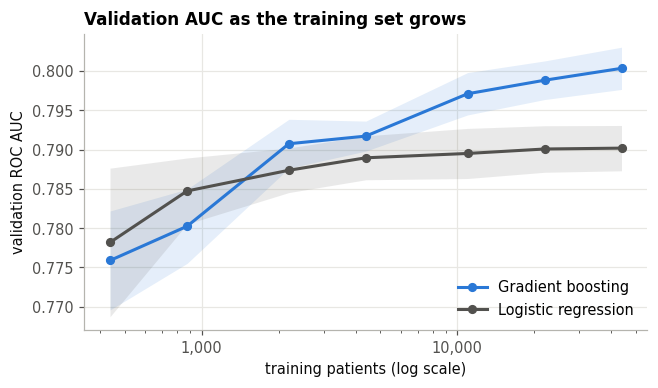

model,Gradient boosting,Logistic regression
patients,,
438,0.7759,0.7782
877,0.7802,0.7847
2194,0.7907,0.7874
4388,0.7917,0.7890
10971,0.7971,0.7895
21943,0.7988,0.7901
43887,0.8003,0.7902


In [29]:
curve = learning_curve_auc(train, {name: searches[name].best_estimator_
                                          for name in ["Logistic regression", "Gradient boosting"]})
fig, ax = plt.subplots(figsize=(6.6, 3.5))
for name, g in curve.groupby("model"):
    colour = NO_CVD if name == "Gradient boosting" else MUTED
    ax.plot(g["patients"], g["auc"], "-o", color=colour, lw=2, ms=5, label=name)
    ax.fill_between(g["patients"], g["auc"] - g["auc_sd"], g["auc"] + g["auc_sd"], color=colour, alpha=0.12, lw=0)
ax.set(xscale="log", xlabel="training patients (log scale)", ylabel="validation ROC AUC",
       title="Validation AUC as the training set grows")
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.legend(loc="lower right")
fig.savefig(FIGURES / "fig7_learning_curve.png")
plt.show()
curve.pivot(index="patients", columns="model", values="auc").style.format("{:.4f}")

The two curves tell different stories:

- **Logistic regression levels off early.** Its validation AUC gains only 0.003 between 2,000 and
  44,000 patients.
- **Gradient boosting keeps improving, but slowly.** It needs more patients to estimate its curves and
  interactions, overtakes logistic regression at around 2,000 patients, and keeps improving. But the
  last doubling, from 22,000 to 44,000 patients, adds only 0.0015.

More patients of the same kind would therefore add little. Together with the closeness of very
different algorithms (Section 7.2) and the flatness of their searches, this suggests that the limit
near 0.80 AUC (about 73% accuracy) lies mainly in what the eleven recorded values can tell, not in
the amount of data or the choice of algorithm. It is a reasoned reading, not a proof: other models
or other features could still do somewhat better.

### 7.5 The chosen model

In [30]:
chosen = choose_model(comparison)
ml = comparison[comparison["kind"] == "machine learning"]
best = ml["auc"].idxmax()
se = ml.loc[best, "auc_sd"] / np.sqrt(CV_FOLDS)
print(f"best cross-validated AUC: {best} ({ml.loc[best, 'auc']:.4f}, fold SD {ml.loc[best, 'auc_sd']:.4f})")
print(f"one standard error: {se:.4f}; within it of the best: {', '.join(ml.index[ml['auc'] >= ml.loc[best, 'auc'] - se])}")
print(f"chosen by the one-standard-error rule: {chosen}, setting: {ml.loc[chosen, 'best setting']}")
gb, rf = searches["Gradient boosting"].best_estimator_, searches["Random forest"].best_estimator_
print(f"model size: gradient boosting {gb.n_iter_} trees of at most {gb.max_leaf_nodes} leaves; "
      f"random forest {len(rf.estimators_)} trees with {sum(t.tree_.n_leaves for t in rf.estimators_):,} leaves in all")

best cross-validated AUC: Gradient boosting (0.8005, fold SD 0.0029)
one standard error: 0.0013; within it of the best: Random forest, Gradient boosting, Neural network (MLP)
chosen by the one-standard-error rule: Gradient boosting, setting: learning_rate=0.01, max_leaf_nodes=15, min_samples_leaf=50
model size: gradient boosting 593 trees of at most 15 leaves; random forest 200 trees with 114,770 leaves in all


Three models are within one standard error (0.0013) of the best: gradient boosting, the neural
network and random forest. The rule fixed in advance then takes the simplest of the tied models, and
in its order gradient boosting comes first. It is also far smaller than the forest (593 trees of at
most 15 leaves, under 9,000 leaves in all, against 114,770). **Gradient boosting is the final
model.** The choice matters little in practice: Section 8.2 shows
how close the three remain on the test set.

## 8. The final model on the test set

### 8.1 Every candidate, scored once

Apart from counts (the class balance in Section 3 and the record checks in Section 4), the 13,722
test patients have not been used so far. Each candidate is now scored on them once, with its
settings and cut-off already fixed:

- The machine-learning models use their selected settings, refitted on all training patients.
- The baselines that need a cut-off use the one chosen on the training patients.
- Confidence intervals come from 2,000 bootstrap resamples of the test patients, the same resamples
  for every candidate.

The helpers for the test-set evaluation: paired bootstrap intervals, out-of-fold predictions, and the
cut-offs chosen on training data.

In [31]:
def bootstrap(y, scores: dict, statistic, n: int = 2000, seed: int = SEED) -> pd.DataFrame:
    """Percentile bootstrap of statistic(y, score) for several scores, resampling the same patients
    for all of them, so differences between scores can be bootstrapped too. One row per resample."""
    y = np.asarray(y)
    scores = {k: np.asarray(v) for k, v in scores.items()}
    rng = np.random.default_rng(seed)
    rows = []
    for _ in range(n):
        idx = rng.integers(0, len(y), len(y))
        rows.append({k: statistic(y[idx], s[idx]) for k, s in scores.items()})
    return pd.DataFrame(rows)


def interval(samples: pd.Series, level: float = 0.95) -> tuple[float, float]:
    a = (1 - level) / 2
    return float(samples.quantile(a)), float(samples.quantile(1 - a))


def out_of_fold(estimator, train: pd.DataFrame, features: list[str] = FEATURES,
                n_jobs: int = N_JOBS) -> np.ndarray:
    """Each training patient's predicted risk from a model that did not see that patient."""
    from sklearn.base import clone
    from sklearn.model_selection import cross_val_predict

    return cross_val_predict(clone(estimator), train[features], train[TARGET], cv=cv_splitter(),
                             method="predict_proba", n_jobs=n_jobs)[:, 1]


def screening_threshold(y, risk, sensitivity: float = 0.80) -> float:
    """The highest cut-off that still detects at least `sensitivity` of the diseased patients."""
    y, risk = np.asarray(y), np.asarray(risk)
    sick = np.sort(risk[y == 1])
    caught = math.ceil(sensitivity * len(sick) - 1e-9)   # patients the cut-off must catch
    return float(sick[len(sick) - caught])


def threshold_at_specificity(y, risk, specificity: float) -> float:
    """The lowest cut-off that still clears at least `specificity` of the healthy patients, i.e. the
    most sensitive operating point at that specificity. Patients at or above the cut-off are flagged."""
    y, risk = np.asarray(y), np.asarray(risk)
    healthy = np.sort(risk[y == 0])
    cleared = math.ceil(specificity * len(healthy) - 1e-9)  # healthy patients that must fall below it
    if cleared == 0:
        return -math.inf
    return float(np.nextafter(healthy[cleared - 1], math.inf))

In [32]:
from sklearn.metrics import roc_auc_score

final = searches[chosen].best_estimator_
y_test = test["cardio"]
RULE = f"Rule: systolic ≥ {SBP_RULE} mmHg"
test_scores = {
    RULE: (test["ap_hi"] >= SBP_RULE).astype(float),
    "Systolic pressure alone": test["ap_hi"].astype(float),
    "Framingham (published)": framingham_risk(test),
    **{name: s.predict_proba(test[FEATURES])[:, 1] for name, s in searches.items()},
}
cutoffs = {name: 0.5 for name in test_scores}
cutoffs["Systolic pressure alone"] = accuracy_threshold(train["cardio"], train["ap_hi"])
cutoffs["Framingham (published)"] = accuracy_threshold(train["cardio"], framingham_risk(train))
predictions = {name: (np.asarray(score) >= cutoffs[name]).astype(int) for name, score in test_scores.items()}

auc_boot = bootstrap(y_test, test_scores, roc_auc_score)
acc_boot = bootstrap(y_test, predictions, lambda y, p: (y == p).mean())
rows = []
for name, score in test_scores.items():
    m = classification_metrics(y_test, score, cutoffs[name])
    lo, hi = interval(auc_boot[name])
    alo, ahi = interval(acc_boot[name])
    rows.append({"model": name, "test AUC": m["auc"], "AUC 95% CI": f"{lo:.3f}-{hi:.3f}",
                 "CV AUC": comparison.loc[name, "auc"], "accuracy": m["accuracy"],
                 "accuracy 95% CI": f"{alo:.1%}-{ahi:.1%}",
                 "sensitivity": m["sensitivity"], "specificity": m["specificity"]})
test_table = pd.DataFrame(rows).set_index("model").sort_values("test AUC", ascending=False)
test_table.to_csv(ROOT / "outputs" / "test_results.csv")
gain_lo, gain_hi = interval(acc_boot[chosen] - acc_boot[RULE])
print(f"systolic pressure alone, cut-off chosen on all training patients: {cutoffs['Systolic pressure alone']:g} mmHg")
print(f"{chosen} minus the rule, accuracy: {(test_table.loc[chosen, 'accuracy'] - test_table.loc[RULE, 'accuracy']) * 100:+.1f} "
      f"points (95% CI {gain_lo * 100:+.1f} to {gain_hi * 100:+.1f})")
test_table.style.format({"test AUC": "{:.3f}", "CV AUC": "{:.3f}", "accuracy": "{:.1%}",
                         "sensitivity": "{:.1%}", "specificity": "{:.1%}"})

systolic pressure alone, cut-off chosen on all training patients: 130 mmHg
Gradient boosting minus the rule, accuracy: +2.3 points (95% CI +1.8 to +2.9)


,test AUC,AUC 95% CI,CV AUC,accuracy,accuracy 95% CI,sensitivity,specificity
model,,,,,,,
Gradient boosting,0.804,0.797-0.811,0.801,73.6%,72.9%-74.4%,68.9%,78.2%
Random forest,0.803,0.796-0.810,0.799,73.4%,72.6%-74.1%,68.5%,78.1%
Neural network (MLP),0.800,0.793-0.808,0.800,73.1%,72.4%-73.9%,70.6%,75.6%
Logistic regression,0.793,0.785-0.800,0.790,72.6%,71.9%-73.3%,66.8%,78.2%
Framingham form (refit),0.780,0.773-0.788,0.780,71.4%,70.6%-72.1%,66.3%,76.3%
Systolic pressure alone,0.754,0.746-0.761,0.751,71.3%,70.6%-72.0%,61.8%,80.6%
Rule: systolic ≥ 130 mmHg,0.712,0.704-0.719,0.712,71.3%,70.6%-72.0%,61.8%,80.6%
Framingham (published),0.693,0.684-0.701,0.696,64.6%,63.8%-65.4%,74.0%,55.5%


**The test set confirms the cross-validation.** Every candidate's test AUC is within 0.004 of its
cross-validated AUC. On patients it has never seen, gradient boosting reaches an AUC of 0.804 (95% CI
0.797-0.811) and 73.6% accuracy (72.9-74.4%), against 71.3% for the systolic ≥ 130 rule: a gain of
2.3 points (95% CI 1.8 to 2.9). The test set re-orders the two runners-up (random forest 0.803, the
neural network 0.800), a reminder that their cross-validated differences were within the noise.

Why does the published Framingham score rank these patients so poorly? Its weights can be checked
one at a time:

In [33]:
fram = framingham_risk(test)
rows = []
for label, mask in [("women", test["male"] == 0), ("men", test["male"] == 1), ("everyone", test["male"] >= 0)]:
    rows.append({"patients": label, "share with CVD": y_test[mask].mean(), "mean Framingham risk": fram[mask].mean(),
                 "Framingham AUC": roc_auc_score(y_test[mask], fram[mask]),
                 "systolic alone AUC": roc_auc_score(y_test[mask], test.loc[mask, "ap_hi"])})
print("published Framingham AUC with the smoking term switched off:",
      f"{roc_auc_score(y_test, framingham_risk(test.assign(smoke=0))):.3f}")
(pd.DataFrame(rows).set_index("patients")
 .style.format({"share with CVD": "{:.1%}", "mean Framingham risk": "{:.1%}", "Framingham AUC": "{:.3f}",
                "systolic alone AUC": "{:.3f}"}))

published Framingham AUC with the smoking term switched off: 0.709


,share with CVD,mean Framingham risk,Framingham AUC,systolic alone AUC
patients,,,,
women,49.2%,7.0%,0.752,0.756
men,49.9%,15.9%,0.695,0.752
everyone,49.4%,10.2%,0.693,0.754


Two of the published weights go wrong for these patients. **Sex:** the equations give men about
twice the risk of women (a mean of 15.9% against 7.0%), but CVD is about equally common in both
sexes here (49.9% and 49.2%). Within women, the published score ranks patients about as well as
systolic pressure alone (AUC 0.752 against 0.756); within men it does worse (0.695 against 0.752).
**Smoking:** the score adds risk for smokers, while smokers in this data have slightly less CVD
(Section 5.2); switching the smoking term off raises the overall AUC from 0.693 to 0.709. The
published equations were built for a different population and a different question, and their
weights must be re-estimated before they are used on data like this.

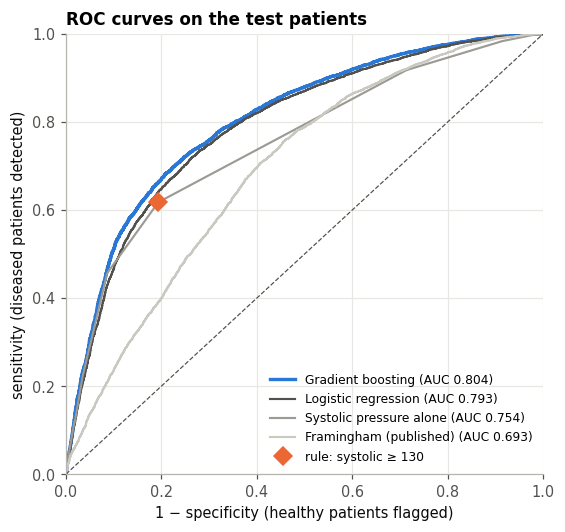

In [34]:
from sklearn.metrics import roc_curve

fig, ax = plt.subplots(figsize=(5.6, 5.2))
for name, colour, lw in [(chosen, NO_CVD, 2.2), ("Logistic regression", MUTED, 1.4),
                         ("Systolic pressure alone", "#9b9a94", 1.4), ("Framingham (published)", "#c9c8c1", 1.4)]:
    fpr, tpr, _ = roc_curve(y_test, test_scores[name])
    ax.plot(fpr, tpr, color=colour, lw=lw, label=f"{name} (AUC {roc_auc_score(y_test, test_scores[name]):.3f})")
rule = classification_metrics(y_test, test_scores[RULE], 0.5)
ax.plot(1 - rule["specificity"], rule["sensitivity"], "D", color=CVD, ms=8, label=f"rule: systolic ≥ {SBP_RULE}")
ax.plot([0, 1], [0, 1], ls="--", lw=0.8, color=MUTED)
ax.set(xlabel="1 − specificity (healthy patients flagged)", ylabel="sensitivity (diseased patients detected)",
       title="ROC curves on the test patients", xlim=(0, 1), ylim=(0, 1))
ax.legend(loc="lower right", fontsize=8)
fig.savefig(FIGURES / "fig8_roc_test.png")
plt.show()

The rule is one point on the ROC plane; the model is a whole curve. To compare them at the rule's own
operating point without touching the test set, the model's cut-off is chosen on the training
patients: the lowest cut-off at which the model, using out-of-fold predictions, clears at least as
many healthy training patients as the rule does. Both are then scored once on the test patients:

In [35]:
oof = out_of_fold(final, train)
rule_specificity_train = (train.loc[train["cardio"] == 0, "ap_hi"] < SBP_RULE).mean()
cut_rule = threshold_at_specificity(train["cardio"], oof, rule_specificity_train)
flags_model = (np.asarray(test_scores[chosen]) >= cut_rule).astype(int)
flags_rule = predictions[RULE]
y = y_test.to_numpy()
detected = bootstrap(y, {"model": flags_model, "rule": flags_rule}, lambda t, f: int(((f == 1) & (t == 1)).sum()))
flagged = bootstrap(y, {"model": flags_model, "rule": flags_rule}, lambda t, f: int(((f == 1) & (t == 0)).sum()))
more = int(((flags_model == 1) & (y == 1)).sum() - ((flags_rule == 1) & (y == 1)).sum())
extra = int(((flags_model == 1) & (y == 0)).sum() - ((flags_rule == 1) & (y == 0)).sum())
lo, hi = interval(detected["model"] - detected["rule"])
flo, fhi = interval(flagged["model"] - flagged["rule"])
print(f"cut-off chosen on training patients: {cut_rule:.3f} (rule's specificity there: {rule_specificity_train:.1%})")
for label, f in [("rule", flags_rule), (chosen, flags_model)]:
    m = classification_metrics(y, f, 0.5)
    print(f"  {label:<20} test sensitivity {m['sensitivity']:.1%}, specificity {m['specificity']:.1%}")
print(f"diseased test patients detected, model minus rule: {more:+,} (95% CI {lo:+.0f} to {hi:+.0f}) "
      f"of {int(y.sum()):,}")
print(f"healthy test patients flagged, model minus rule: {extra:+,} (95% CI {flo:+.0f} to {fhi:+.0f}) "
      f"of {int((y == 0).sum()):,}")

cut-off chosen on training patients: 0.531 (rule's specificity there: 80.7%)
  rule                 test sensitivity 61.8%, specificity 80.6%
  Gradient boosting    test sensitivity 65.8%, specificity 81.0%
diseased test patients detected, model minus rule: +274 (95% CI +220 to +332) of 6,785
healthy test patients flagged, model minus rule: -29 (95% CI -76 to +19) of 6,937


At an operating point chosen without the test set, the model detects 65.8% of the diseased test
patients where the rule detects 61.8%, at a slightly higher specificity (81.0% against 80.6%). That
is 274 more of the 6,785 diseased test patients (95% CI 220 to 332), with 29 fewer healthy patients
flagged (95% CI 76 fewer to 19 more: no clear difference). This is the most concrete form of the
answer to Q1: about one more sick patient found for every 25 diseased patients examined, at no clear
cost in false alarms.

### 8.2 How large are the differences?

The same bootstrap resamples score every model, so each AUC difference can be given its own
interval. These intervals cover the sampling of test patients only: each model was fitted once, with
one seed. Five comparisons are made at once, so a Bonferroni-adjusted interval (99%) is shown too.

In [36]:
pairs = [(chosen, other) for other in ["Random forest", "Neural network (MLP)", "Logistic regression",
                                        "Framingham form (refit)", "Systolic pressure alone"] if other != chosen]
diffs = []
for a, b in pairs:
    d = auc_boot[a] - auc_boot[b]
    lo, hi = interval(d)
    blo, bhi = interval(d, level=1 - 0.05 / len(pairs))
    diffs.append({"comparison": f"{a} − {b}",
                  "AUC difference": roc_auc_score(y_test, test_scores[a]) - roc_auc_score(y_test, test_scores[b]),
                  "95% CI": f"{lo:+.4f} to {hi:+.4f}", f"{1 - 0.05 / len(pairs):.0%} CI (adjusted)": f"{blo:+.4f} to {bhi:+.4f}"})
pd.DataFrame(diffs).set_index("comparison").style.format({"AUC difference": "{:+.4f}"})

,AUC difference,95% CI,99% CI (adjusted)
comparison,,,
Gradient boosting − Random forest,+0.0015,+0.0002 to +0.0028,-0.0003 to +0.0032
Gradient boosting − Neural network (MLP),+0.0040,+0.0024 to +0.0056,+0.0020 to +0.0062
Gradient boosting − Logistic regression,+0.0119,+0.0094 to +0.0144,+0.0086 to +0.0151
Gradient boosting − Framingham form (refit),+0.0239,+0.0205 to +0.0273,+0.0196 to +0.0286
Gradient boosting − Systolic pressure alone,+0.0504,+0.0457 to +0.0551,+0.0443 to +0.0569


- **Over random forest and the neural network**, the lead is small: 0.0015 and 0.0040 AUC. The
  random-forest interval excludes zero at 95% but not once the five comparisons are adjusted for; the
  lead over the network survives the adjustment but is still only 0.004. None of these differences
  would change a clinical decision.
- **Over logistic regression** the lead is 0.012 (95% CI 0.009 to 0.014). Small, but consistent: the
  trees capture something a linear model on these features does not (Section 8.4 suggests what).
- **Over Framingham's terms refitted** (0.024) and **over systolic pressure alone** (0.050), the gaps
  are clear.

### 8.3 Choosing the threshold

A predicted risk becomes a verdict only through a cut-off. For a well-calibrated model (Section
9.3), 0.5 is the cut-off that maximises expected accuracy. A screening programme usually cares more
about not missing sick patients, so a second cut-off is chosen **on the training patients**: the
highest one that detects at least 80% of the diseased training patients, using predictions from
models that did not see them (the out-of-fold predictions of Section 8.1).

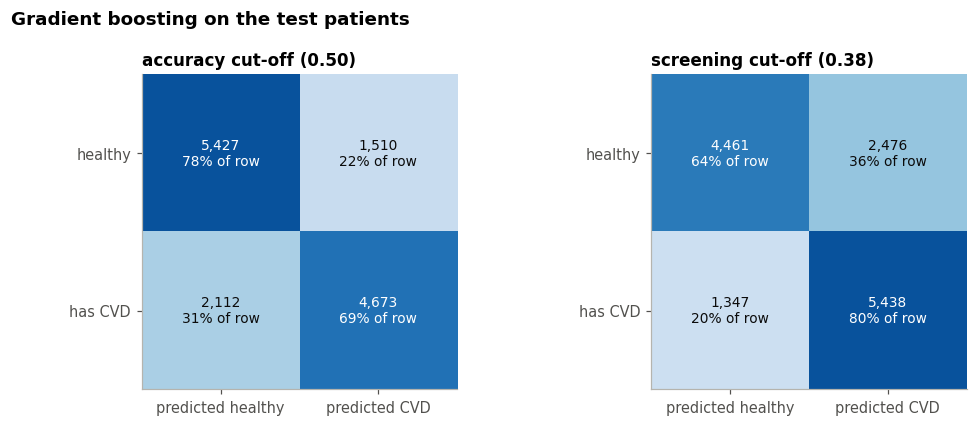

,accuracy,sensitivity,specificity
cut-off,,,
accuracy cut-off (0.50),73.6%,68.9%,78.2%
screening cut-off (0.38),72.1%,80.1%,64.3%


In [37]:
from sklearn.metrics import confusion_matrix

cut_screen = screening_threshold(train["cardio"], oof, 0.80)
risk_test = test_scores[chosen]

fig, axes = plt.subplots(1, 2, figsize=(9.6, 3.9))
summary = []
for ax, (label, cut) in zip(axes, [("accuracy cut-off (0.50)", 0.5), (f"screening cut-off ({cut_screen:.2f})", cut_screen)]):
    cm = confusion_matrix(y_test, risk_test >= cut)
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=cm.max() * 1.15)
    for (i, j), v in np.ndenumerate(cm):
        ax.text(j, i, f"{v:,}\n{v / cm[i].sum():.0%} of row", ha="center", va="center", fontsize=9,
                color="white" if v > cm.max() * 0.6 else INK)
    ax.set_xticks([0, 1], ["predicted healthy", "predicted CVD"])
    ax.set_yticks([0, 1], ["healthy", "has CVD"])
    ax.grid(False)
    ax.set_title(label)
    m = classification_metrics(y_test, risk_test, cut)
    summary.append({"cut-off": label, **m})
fig.suptitle(f"{chosen} on the test patients", x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout()
fig.savefig(FIGURES / "fig9_confusion_matrices.png")
plt.show()
pd.DataFrame(summary).set_index("cut-off").drop(columns="auc").style.format("{:.1%}")

The screening cut-off, chosen on the training patients alone, detects 80.1% of the diseased test
patients: the target carries over to unseen patients. The price is specificity. At 0.50 the model
misses 2,112 of the 6,785 diseased test patients and flags 1,510 of the 6,937 healthy ones. At the
screening cut-off it misses 1,347 and flags 2,476. Which trade-off is right is not a statistical
question. It depends on what follows a positive result. For a cheap follow-up examination, the
screening cut-off is the sensible choice.

### 8.4 What drives the predictions

Three complementary views. **Grouped permutation importance** asks how much test AUC is lost when a
factor is scrambled across patients, that is, how much this fitted model leans on it. Related
features are scrambled together, so the blood-pressure features cannot cover for one another.
**Retraining without a factor** asks a different question: what a model of the same kind can do
without it. **Partial dependence** asks how the average predicted risk changes as one factor is
varied for everyone.

In [38]:
# Features that carry the same information are permuted together: permuting systolic pressure alone
# would leave mean arterial pressure, pulse pressure and the stage to stand in for it.
FEATURE_GROUPS = {
    "blood pressure": ["ap_hi", "ap_lo", "pulse_pressure", "mean_arterial_pressure", "bp_stage"],
    "age": ["age_years"],
    "body size (height, weight, BMI)": ["height", "weight", "bmi"],
    "cholesterol": ["cholesterol"],
    "glucose": ["gluc"],
    "physical activity": ["active"],
    "smoking": ["smoke"],
    "alcohol": ["alco"],
    "sex": ["male"],
}


def grouped_permutation_importance(model, df: pd.DataFrame, groups: dict = FEATURE_GROUPS,
                                   n_repeats: int = 10, seed: int = SEED) -> pd.DataFrame:
    """Drop in AUC when each group of features is shuffled across patients (the same shuffle for every
    column of the group, so the group stays internally consistent but loses its link to the diagnosis)."""
    from sklearn.metrics import roc_auc_score

    rng = np.random.default_rng(seed)
    X, y = df[FEATURES], df[TARGET].to_numpy()
    base = roc_auc_score(y, model.predict_proba(X)[:, 1])
    rows = []
    for name, cols in groups.items():
        drops = []
        for _ in range(n_repeats):
            shuffled = X.copy()
            order = rng.permutation(len(X))
            shuffled[cols] = X[cols].to_numpy()[order]
            drops.append(base - roc_auc_score(y, model.predict_proba(shuffled)[:, 1]))
        rows.append({"features": name, "auc drop": np.mean(drops), "sd": np.std(drops, ddof=1)})
    return pd.DataFrame(rows).set_index("features").sort_values("auc drop", ascending=False)


def partial_dependence_curve(model, df: pd.DataFrame, feature: str, values) -> pd.Series:
    """Average predicted risk when every patient's `feature` is set to each value in turn, with the
    features derived from it recomputed, so the model never sees an impossible combination.

    For systolic pressure, a diastolic reading that would reach the new systolic value is capped 10 mmHg
    below it; at the low end of the curve this also lowers some diastolic readings (about 7% of patients
    at 100 mmHg, under 1% from 120 mmHg up), so that end is not a pure systolic effect."""
    out = {}
    for v in values:
        d = df.copy()
        d[feature] = v
        if feature == "ap_hi":  # keep every diastolic reading below the systolic one it is paired with
            d["ap_lo"] = np.minimum(d["ap_lo"], v - 10)
        d = add_features(d.drop(columns=DERIVED_FEATURES))
        out[v] = model.predict_proba(d[FEATURES])[:, 1].mean()
    return pd.Series(out, name=feature)


def drop_group_importance(estimator, train: pd.DataFrame, groups: dict = FEATURE_GROUPS,
                          n_jobs: int = N_JOBS) -> pd.DataFrame:
    """Cross-validated AUC (training patients) of the same model retrained without each group of
    features. Unlike permutation importance, this asks what the data can do without a group, not how
    much one fitted model leans on it."""
    from sklearn.base import clone
    from sklearn.model_selection import cross_val_score

    def cv_auc(cols):
        return cross_val_score(clone(estimator), train[cols], train[TARGET], cv=cv_splitter(),
                               scoring="roc_auc", n_jobs=n_jobs).mean()

    full = cv_auc(FEATURES)
    rows = [{"features left out": "none (all 15)", "CV AUC": full, "AUC lost": 0.0}]
    for name, cols in groups.items():
        auc = cv_auc([f for f in FEATURES if f not in cols])
        rows.append({"features left out": name, "CV AUC": auc, "AUC lost": full - auc})
    return pd.DataFrame(rows).set_index("features left out")

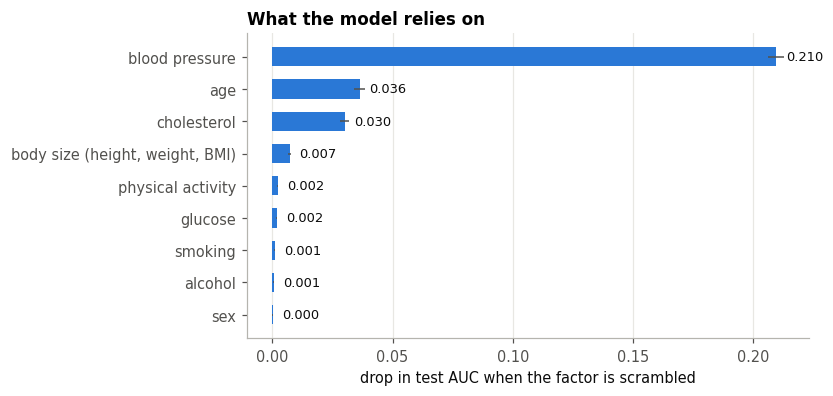

In [39]:
importance = grouped_permutation_importance(final, test)

fig, ax = plt.subplots(figsize=(6.6, 3.6))
order = importance.iloc[::-1]
ax.barh(order.index, order["auc drop"], xerr=order["sd"], color=NO_CVD, height=0.6,
        error_kw={"ecolor": MUTED, "elinewidth": 1})
for yi, v in enumerate(order["auc drop"]):
    ax.text(v + 0.004, yi, f"{v:.3f}", va="center", fontsize=8.5, color=INK)
ax.set(xlabel="drop in test AUC when the factor is scrambled", title="What the model relies on")
ax.grid(axis="y", visible=False)
fig.savefig(FIGURES / "fig10_importance.png")
plt.show()

In [40]:
retrained = drop_group_importance(final, train)
retrained.style.format("{:.4f}")

,CV AUC,AUC lost
features left out,,
none (all 15),0.8005,0.0000
blood pressure,0.7019,0.0986
age,0.7804,0.0201
"body size (height, weight, BMI)",0.7984,0.0021
cholesterol,0.7914,0.0091
glucose,0.7992,0.0013
physical activity,0.7995,0.0010
smoking,0.8002,0.0003
alcohol,0.8003,0.0002


**Blood pressure dominates.** Scrambling the five blood-pressure features costs this model 0.210 test
AUC; age (0.036) and cholesterol (0.030) follow, body size adds a little (0.007), and glucose, the
three lifestyle answers and sex each contribute 0.002 or less. Retraining tells the same story
in different numbers. A model built without blood pressure still reaches a cross-validated AUC of
0.702: the other factors carry real information, they are simply weaker. Leaving out age costs
0.020, cholesterol 0.009, and every other factor about 0.002 or less. The two views agree on the
top four, in the same order, which matches the exploratory analysis in Section 5.

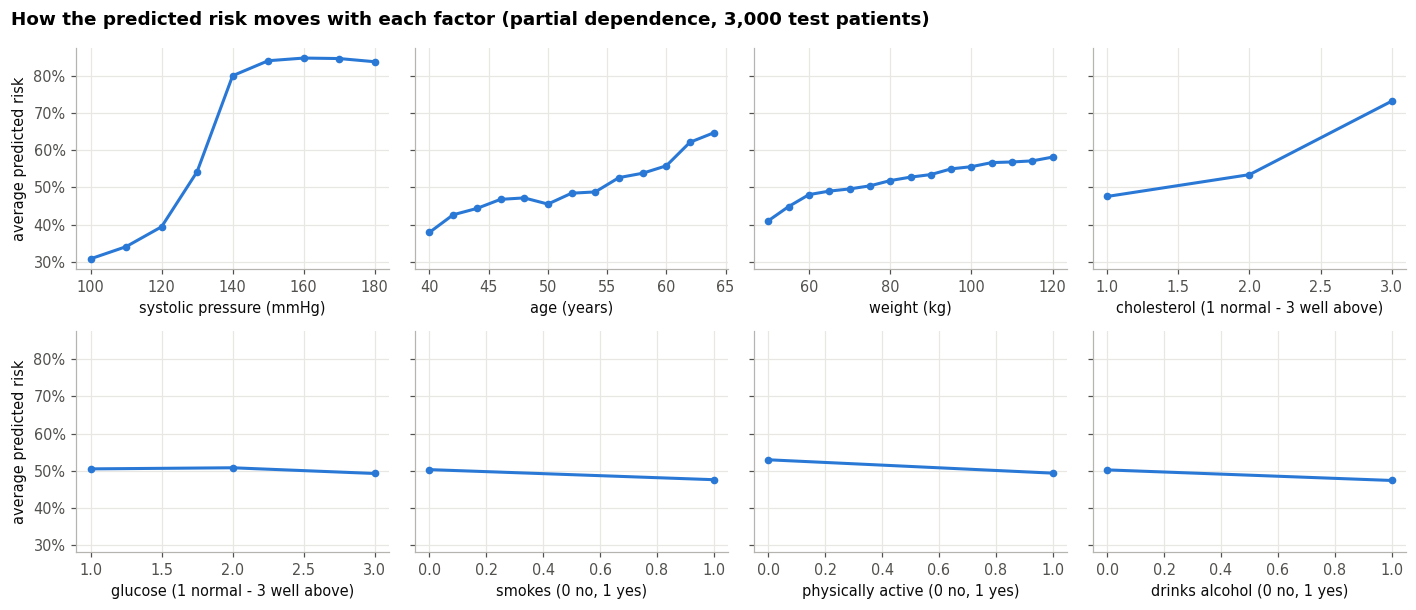

In [41]:
curves = [("ap_hi", range(100, 181, 10), "systolic pressure (mmHg)"),
          ("age_years", range(40, 66, 2), "age (years)"),
          ("weight", range(50, 121, 5), "weight (kg)"),
          ("cholesterol", [1, 2, 3], "cholesterol (1 normal - 3 well above)"),
          ("gluc", [1, 2, 3], "glucose (1 normal - 3 well above)"),
          ("smoke", [0, 1], "smokes (0 no, 1 yes)"),
          ("active", [0, 1], "physically active (0 no, 1 yes)"),
          ("alco", [0, 1], "drinks alcohol (0 no, 1 yes)")]
sample = test.sample(3000, random_state=SEED)

fig, axes = plt.subplots(2, 4, figsize=(13, 5.6), sharey=True)
for ax, (feature, values, label) in zip(axes.flat, curves):
    pdc = partial_dependence_curve(final, sample, feature, list(values))
    ax.plot(pdc.index, pdc.values, "-o", color=NO_CVD, lw=2, ms=4)
    ax.set(xlabel=label)
    ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1, decimals=0))
for ax in axes[:, 0]:
    ax.set_ylabel("average predicted risk")
fig.suptitle("How the predicted risk moves with each factor (partial dependence, 3,000 test patients)",
             x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout()
fig.savefig(FIGURES / "fig11_partial_dependence.png")
plt.show()

The partial-dependence curves show the *shape* of each effect:

- **Systolic pressure works more like a switch than a slope.** The average predicted risk is about
  31-39% from 100 to 120 mmHg, rises to 54% at 130 mmHg and 80% at 140 mmHg, then levels off at about
  84%. Two things may make the steps sharper than the biology itself: the stage feature builds the
  guideline's thresholds into the data (Section 6), and almost every reading is a multiple of 10.
  Still, the shape is clearly not a straight line, and a logistic regression, which adds each
  feature's effect along a straight line in log-odds, can only approximate it. This may explain part
  of its 0.012 AUC gap. (At 100-110 mmHg the curve also lowers some diastolic readings, so that end is
  not a pure systolic effect.)
- **Age, weight and cholesterol raise the risk steadily.** Age goes from about 38% at 40 to 65% at 64,
  weight from about 41% at 50 kg to 58% at 120 kg, and cholesterol "well above normal" adds about 25
  percentage points.
- **Glucose, smoking and alcohol leave the risk flat or slightly lower it.** Physical activity lowers
  it slightly too, which is what medicine expects. For smoking this is the pattern of Section 5.2.
  Glucose's own disease rate rises (Section 5.1), but the model gives it
  little weight, slightly negative at the highest level; its correlation with cholesterol (0.45) may
  explain part of this. **These curves describe associations in this dataset and must not be read as
  causal effects**: nothing here suggests that smoking is harmless.

### 8.5 A points score a doctor can use on paper

If the best model gains only a little over simpler ones, the most useful result might be a
transparent score. Here each factor is cut into clinical bands, a logistic regression is fitted on
the bands, and its coefficients are rounded to whole points (one point = 0.1 in log-odds). The total
then maps to a risk: the share of training patients with CVD at that total, smoothed so that more
points always mean more risk.

In [42]:
POINTS_BANDS = {
    "age_years": ([0, 45, 50, 55, 60, 200], ["<45", "45-49", "50-54", "55-59", "60+"]),
    "ap_hi": ([0, 120, 130, 140, 160, 400], ["<120", "120-129", "130-139", "140-159", "160+"]),
    "bmi": ([0, 25, 30, 35, 200], ["<25", "25-29.9", "30-34.9", "35+"]),
}
POINTS_LEVELS = {"cholesterol": {1: "normal", 2: "above normal", 3: "well above normal"},
                 "gluc": {1: "normal", 2: "above normal", 3: "well above normal"},
                 "smoke": {0: "no", 1: "yes"}, "alco": {0: "no", 1: "yes"}, "active": {0: "no", 1: "yes"}}
# The clinical scorecard (Section 8.5): measured values only, and only those whose training-set points
# go the way medicine expects. The self-reported answers are left out whatever their sign (reverse
# causation makes them unreliable here), and glucose because its training-set points are negative.
CLINICAL_FACTORS = ["age_years", "ap_hi", "bmi", "cholesterol"]
POINTS_LABELS = {"age_years": "Age (years)", "ap_hi": "Systolic pressure (mmHg)", "bmi": "BMI (kg/m²)",
                 "cholesterol": "Cholesterol", "gluc": "Glucose", "smoke": "Smokes", "alco": "Drinks alcohol",
                 "active": "Physically active"}


class PointsScore:
    """A paper scorecard: each factor's band earns whole points, and the total maps to a risk.

    Fitted as a logistic regression on banded factors (lowest band as reference). One point is worth
    `unit` in log-odds, so every coefficient is rounded to whole points. The total is then mapped back
    to a risk by isotonic regression on the training patients: the share with CVD at each total,
    forced to rise with the total. (A logistic curve in the total is too rigid here: the large step in
    points between systolic bands makes the totals cluster, and the curve misstates both ends.)
    """

    def __init__(self, unit: float = 0.1, factors: list[str] | None = None):
        self.unit = unit
        self.factors = factors or [*POINTS_BANDS, *POINTS_LEVELS]

    def _bands(self, df: pd.DataFrame) -> pd.DataFrame:
        cols = {}
        for col in self.factors:
            if col in POINTS_BANDS:
                edges, labels = POINTS_BANDS[col]
                cols[col] = pd.Categorical(pd.cut(df[col], edges, labels=labels, right=False), labels)
            else:
                levels = POINTS_LEVELS[col]
                cols[col] = pd.Categorical(df[col].map(levels), list(levels.values()))
        bands = pd.DataFrame(cols, index=df.index)
        outside = [c for c in bands if bands[c].isna().any()]
        if outside:  # never score a value the card has no band for as if it were the reference band
            raise ValueError("values outside the scorecard's bands: " + ", ".join(outside))
        return bands

    def _design(self, df: pd.DataFrame) -> pd.DataFrame:
        return pd.get_dummies(self._bands(df), drop_first=True, dtype=float)

    def fit(self, df: pd.DataFrame, y):
        from sklearn.isotonic import IsotonicRegression
        from sklearn.linear_model import LogisticRegression

        X = self._design(df)
        lr = LogisticRegression(C=1.0, max_iter=5000).fit(X, y)
        self.points_ = pd.Series(np.round(lr.coef_[0] / self.unit).astype(int), index=X.columns)
        iso = IsotonicRegression(y_min=0, y_max=1, out_of_bounds="clip").fit(self.total(df), np.asarray(y))
        self.risk_points_ = np.asarray(iso.X_thresholds_, dtype=float)
        self.risk_values_ = np.asarray(iso.y_thresholds_, dtype=float)
        return self

    def total(self, df: pd.DataFrame) -> pd.Series:
        return (self._design(df)[self.points_.index] @ self.points_).rename("points")

    def _risk(self, totals) -> np.ndarray:
        totals = np.asarray(totals, dtype=float)
        risk = np.interp(totals, self.risk_points_, self.risk_values_)
        # isotonic regression can give neighbouring totals the same risk; a millionth-sized nudge keeps
        # more points always meaning more risk, so ranking by risk is ranking by points
        span = max(self.risk_points_[-1] - self.risk_points_[0], 1.0)
        return risk * (1 - 1e-6) + 1e-6 * np.clip((totals - self.risk_points_[0]) / span, 0, 1)

    def predict_proba(self, df: pd.DataFrame) -> np.ndarray:
        return self._risk(self.total(df))

    def to_dict(self) -> dict:
        """Plain numbers only, so a saved scorecard loads in any program, with no pickled class."""
        return {"unit": self.unit, "factors": list(self.factors),
                "points": {k: int(v) for k, v in self.points_.items()},
                "risk_points": self.risk_points_.tolist(), "risk_values": self.risk_values_.tolist()}

    @classmethod
    def from_dict(cls, d: dict) -> "PointsScore":
        card = cls(d["unit"], d["factors"])
        card.points_ = pd.Series(d["points"], dtype=int)
        card.risk_points_ = np.asarray(d["risk_points"], dtype=float)
        card.risk_values_ = np.asarray(d["risk_values"], dtype=float)
        return card

    def table(self) -> pd.DataFrame:
        """The scorecard: every band of every factor with its points (reference bands score 0)."""
        rows = []
        for col in self.factors:
            labels = POINTS_BANDS[col][1] if col in POINTS_BANDS else list(POINTS_LEVELS[col].values())
            for label in labels:
                rows.append({"factor": POINTS_LABELS[col], "band": label,
                             "points": int(self.points_.get(f"{col}_{label}", 0))})
        return pd.DataFrame(rows)

    def risk_by_total(self, totals) -> pd.Series:
        totals = np.asarray(list(totals))
        return pd.Series(self._risk(totals), index=totals)

In [43]:
points = PointsScore().fit(train, train["cardio"])
card = points.table()
card.set_index(["factor", "band"])

points
factor                   band                     
Age (years)              <45                     0
                         45-49                   4
                         50-54                   5
                         55-59                   8
                         60+                    11
Systolic pressure (mmHg) <120                    0
                         120-129                 5
                         130-139                13
                         140-159                25
                         160+                   27
BMI (kg/m²)              <25                     0
                         25-29.9                 2
                         30-34.9                 3
                         35+                     4
Cholesterol              normal                  0
                         above normal            3
                         well above normal      11
Glucose                  normal                  0
                         above normal            0
                         well above normal      -3
Smokes                   no                      0
                         yes                    -2
Drinks alcohol           no                      0
                         yes                    -2
Physically active        no                      0
                         yes                    -2

The scorecard reads like the model: systolic pressure earns up to 27 points, age up to 11,
cholesterol up to 11, and BMI up to 4. Three factors earn points against the direction medicine
expects: smoking (−2), alcohol (−2) and glucose "well above normal" (−3). No clinician could hand out
a score that rewards smoking or high glucose. For smoking this may be the reverse causation of
Section 5.2; for glucose, its overlap with cholesterol (Section 8.4). Physical activity also earns
−2, but that is the protective direction medicine expects.

So a **clinical version** keeps the factors that are *measured* at the examination and whose points
in this training fit go the way medicine expects. That removes the three self-reported answers,
whatever their sign (they are the answers most open to reverse causation), and glucose, and keeps
age, systolic pressure, BMI and cholesterol. The rule was set after seeing the full card's points,
which come from the training patients only. It is not blind to the test set, though: an earlier
version of this report had already chosen the same four factors, partly because the others weighed
little in the test-set importances of Section 8.4. The training patients alone point the same way
(leaving out any of the other factors costs 0.002 AUC or less in cross-validation, Section 8.4), and
the clinical card scores slightly below the full card on the test set, so this history does not
flatter its result.

In [44]:
clinical = PointsScore(factors=CLINICAL_FACTORS).fit(train, train["cardio"])
test_scores["Points score (all factors)"] = points.predict_proba(test)
test_scores["Points score (clinical)"] = clinical.predict_proba(test)
cards = ["Points score (all factors)", "Points score (clinical)"]
boot_cards = bootstrap(y_test, {k: test_scores[k] for k in cards + [chosen]}, roc_auc_score)
for name in cards + ["Logistic regression", chosen]:
    m = classification_metrics(y_test, test_scores[name], 0.5)
    ci = "(95% CI {:.3f}-{:.3f})".format(*interval(boot_cards[name])) if name in boot_cards else ""
    print(f"{name:<28} AUC {m['auc']:.3f} {ci:<20} accuracy {m['accuracy']:.1%}")
lo, hi = interval(boot_cards[chosen] - boot_cards["Points score (clinical)"])
gap = roc_auc_score(y_test, test_scores[chosen]) - roc_auc_score(y_test, test_scores["Points score (clinical)"])
print(f"{chosen} minus the clinical card: AUC {gap:+.4f} (95% CI {lo:+.4f} to {hi:+.4f})")
clinical.table().set_index(["factor", "band"]).T

Points score (all factors)   AUC 0.795 (95% CI 0.788-0.803) accuracy 73.0%
Points score (clinical)      AUC 0.793 (95% CI 0.785-0.800) accuracy 72.4%
Logistic regression          AUC 0.793                      accuracy 72.6%
Gradient boosting            AUC 0.804 (95% CI 0.797-0.811) accuracy 73.6%
Gradient boosting minus the clinical card: AUC +0.0117 (95% CI +0.0094 to +0.0142)


factor Age (years)                       Systolic pressure (mmHg)          \
band           <45 45-49 50-54 55-59 60+                     <120 120-129   
points           0     4     5     8  11                        0       5   

factor                      BMI (kg/m²)                     Cholesterol  \
band   130-139 140-159 160+         <25 25-29.9 30-34.9 35+      normal   
points      13      25   27           0       2       3   4           0   

factor                                 
band   above normal well above normal  
points            3                 9

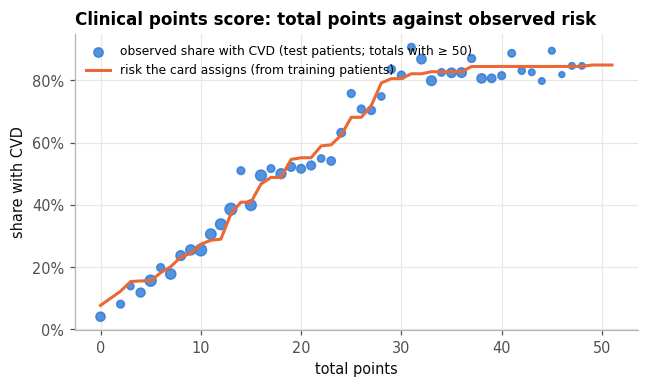

In [45]:
totals = clinical.total(test)
observed = test.groupby(totals)["cardio"].agg(["mean", "size"])
observed = observed[observed["size"] >= 50]
grid = np.arange(totals.min(), totals.max() + 1)
fig, ax = plt.subplots(figsize=(6.6, 3.5))
ax.scatter(observed.index, observed["mean"], s=np.sqrt(observed["size"]) * 2, color=NO_CVD, alpha=0.8,
           label="observed share with CVD (test patients; totals with ≥ 50)")
ax.plot(grid, clinical.risk_by_total(grid), color=CVD, lw=2, label="risk the card assigns (from training patients)")
ax.set(xlabel="total points", ylabel="share with CVD", title="Clinical points score: total points against observed risk")
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1, decimals=0))
ax.legend(loc="upper left", fontsize=8)
fig.savefig(FIGURES / "fig12_points_score.png")
plt.show()

**Dropping the self-reported answers and glucose costs almost nothing.** The four-factor clinical
card reaches an AUC of 0.793 (95% CI 0.785-0.800) and 72.4% accuracy: the same AUC as logistic
regression on all fifteen features to three decimals, with 0.2 points less accuracy, and 0.012 AUC
below gradient boosting (95% CI 0.009 to 0.014). The full card does a little better (0.795, 73.0%),
as it should with more factors. The card's risks come straight from the training patients' observed
rates at each total, so they follow the test patients' rates closely in the figure (Section 9.3
checks them with a calibration curve and the Brier score). A doctor with a pen can add up four
numbers (age, systolic pressure, BMI, cholesterol) and get within about one point of the best
model's accuracy. This is in line with Rudin's argument that for tabular problems like this one, an
interpretable model is often nearly as accurate as a black box [9].

## 9. Reliability

Section 8 measured how well the model works. This section asks how far those numbers can be
trusted: how they depend on data-handling choices (Q2), and whether the predicted risks hold up as
risks, for different kinds of patients (Q3).

### 9.1 Does the cleaning strategy matter?

The final gradient-boosting setting and the logistic regression are trained three times: on the raw
training data, on the `drop` training data and on the `repair` training data. All six models are
scored on the same test patients (those whose records pass every check), so only the training data
differs.

The reliability checks of this section: the cleaning-strategy comparison, the test patients that
`drop` removes, a minimal SMOTE, the three deliberate mistakes, subgroup metrics and predictive value
at other prevalences.

In [46]:
def strategy_comparison(estimators: dict, path: Path | str = DATA, n_boot: int = 2000) -> pd.DataFrame:
    """Each estimator trained on each cleaning strategy's training patients and scored on the common
    test patients (those whose records pass every check), so only the training data differs. The AUC
    change against 'drop' gets a 95% paired bootstrap interval over the test patients."""
    from sklearn.base import clone
    from sklearn.metrics import roc_auc_score

    common = train_test("drop", path)[1].set_index("id")
    y = common[TARGET]
    rows, risks = [], {}
    for strategy in STRATEGIES:
        tr, te = train_test(strategy, path)
        te = te.set_index("id").loc[common.index]          # the same patients, in the same order
        for name, est in estimators.items():
            model = clone(est).fit(tr[FEATURES], tr[TARGET])
            risk = model.predict_proba(te[FEATURES])[:, 1]
            risks[(name, strategy)] = risk
            rows.append({"model": name, "strategy": strategy, "training patients": len(tr),
                         "test AUC": roc_auc_score(y, risk), "test accuracy": float(((risk >= 0.5) == y).mean())})
    table = pd.DataFrame(rows)
    table["AUC change vs drop"] = 0.0
    table["95% CI"] = "-"
    for name in estimators:
        boot = bootstrap(y, {s: risks[(name, s)] for s in STRATEGIES}, roc_auc_score, n=n_boot)
        base = table.loc[(table["model"] == name) & (table["strategy"] == "drop"), "test AUC"].iloc[0]
        for s in STRATEGIES:
            row = (table["model"] == name) & (table["strategy"] == s)
            table.loc[row, "AUC change vs drop"] = table.loc[row, "test AUC"].iloc[0] - base
            if s != "drop":
                lo, hi = interval(boot[s] - boot["drop"])
                table.loc[row, "95% CI"] = f"{lo:+.4f} to {hi:+.4f}"
    return table


def excluded_test_patients(model, path: Path | str = DATA) -> pd.DataFrame:
    """The test patients that 'drop' removes as implausible: how many, how often they have CVD, how many
    'repair' recovers, and how the final model (trained on 'drop') scores the recovered ones."""
    from sklearn.metrics import roc_auc_score

    raw = load(path)
    _, test_ids = split_ids(raw)
    raw_test = deduplicate(raw)
    raw_test = raw_test[raw_test["id"].isin(test_ids)]
    valid = train_test("drop", path)[1]
    repaired = train_test("repair", path)[1]
    removed = raw_test[~raw_test["id"].isin(valid["id"])]
    recovered = repaired[repaired["id"].isin(removed["id"])]

    def scored(label, d):
        risk = model.predict_proba(d[FEATURES])[:, 1]
        return {"test patients": label, "patients": len(d), "share with CVD": d[TARGET].mean(),
                "AUC": roc_auc_score(d[TARGET], risk), "accuracy": float(((risk >= 0.5) == d[TARGET]).mean())}

    rows = [scored("valid records (the test set of Section 8)", valid),
            {"test patients": "removed as implausible by 'drop'", "patients": len(removed),
             "share with CVD": removed[TARGET].mean(), "AUC": np.nan, "accuracy": np.nan},
            scored("  of which recovered by 'repair', scored after repair", recovered),
            scored("valid + recovered", pd.concat([valid, recovered]))]
    return pd.DataFrame(rows).set_index("test patients")


def smote(X: np.ndarray, y: np.ndarray, n_new: int, k: int = 5, seed: int = SEED):
    """SMOTE: new patients interpolated between a patient and one of its k nearest neighbours of the
    same class, n_new per class. Written out here because the leakage experiment needs nothing more."""
    from sklearn.neighbors import NearestNeighbors

    rng = np.random.default_rng(seed)
    new_X, new_y = [], []
    for c in np.unique(y):
        Xc = X[y == c]
        _, nbrs = NearestNeighbors(n_neighbors=k + 1).fit(Xc).kneighbors(Xc)
        i = rng.integers(0, len(Xc), n_new)
        j = nbrs[i, rng.integers(1, k + 1, n_new)]
        lam = rng.random((n_new, 1))
        new_X.append(Xc[i] + lam * (Xc[j] - Xc[i]))
        new_y.append(np.full(n_new, c))
    return np.vstack(new_X), np.concatenate(new_y)


def leakage_experiments(train: pd.DataFrame, test: pd.DataFrame, correct_accuracy: float,
                        seed: int = SEED) -> pd.DataFrame:
    """Accuracy 'reported' by pipelines that make mistakes common in published work on this kind of
    data, next to the correct pipeline. Each mistake lets the evaluation see what it should not."""
    from sklearn.ensemble import RandomForestClassifier
    from sklearn.linear_model import LogisticRegression
    from sklearn.model_selection import train_test_split
    from sklearn.neighbors import KNeighborsClassifier
    from sklearn.pipeline import make_pipeline
    from sklearn.preprocessing import StandardScaler

    rows = [{"pipeline": "Correct: model chosen by cross-validation, scored once on unseen patients",
             "model": "gradient boosting", "reported accuracy": correct_accuracy}]

    # 1. scoring the model on the patients it was trained on
    # 50 fully grown trees: enough to show the effect, and they stay well inside the 4 GB container
    forest = RandomForestClassifier(n_estimators=50, min_samples_leaf=1, random_state=seed, n_jobs=N_JOBS)
    forest.fit(train[FEATURES], train[TARGET])
    rows.append({"pipeline": "Mistake 1: accuracy measured on the training patients",
                 "model": "random forest (fully grown trees)",
                 "reported accuracy": forest.score(train[FEATURES], train[TARGET])})
    rows.append({"pipeline": "  (the same forest on unseen patients)", "model": "random forest (fully grown trees)",
                 "reported accuracy": forest.score(test[FEATURES], test[TARGET])})

    # 2. oversampling (SMOTE) the whole dataset, then splitting it. Each model is shown three ways: with
    #    no oversampling and with SMOTE done correctly (training patients only), both scored on unseen
    #    patients, and with SMOTE done before the split
    everything = pd.concat([train, test])
    X, y = everything[FEATURES].to_numpy(float), everything[TARGET].to_numpy()
    sx, sy = smote(X, y, n_new=len(everything), seed=seed)      # n_new per class: the data triples
    Xa, ya = np.vstack([X, sx]), np.concatenate([y, sy])
    Xtr, Xte, ytr, yte = train_test_split(Xa, ya, test_size=TEST_SIZE, stratify=ya, random_state=seed)
    tx, ty = train[FEATURES].to_numpy(float), train[TARGET].to_numpy()
    vx, vy = test[FEATURES].to_numpy(float), test[TARGET].to_numpy()
    tsx, tsy = smote(tx, ty, n_new=len(train), seed=seed)
    knn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=1))
    for label, model in [("k-nearest neighbours (k = 1)", knn), ("random forest (fully grown trees)", forest)]:
        model.fit(tx, ty)
        rows.append({"pipeline": "  (no oversampling, scored on unseen patients)", "model": label,
                     "reported accuracy": model.score(vx, vy)})
        model.fit(np.vstack([tx, tsx]), np.concatenate([ty, tsy]))
        rows.append({"pipeline": "  (SMOTE on the training patients only, scored on unseen patients)",
                     "model": label, "reported accuracy": model.score(vx, vy)})
        model.fit(Xtr, ytr)
        rows.append({"pipeline": "Mistake 2: SMOTE oversampling before the train/test split", "model": label,
                     "reported accuracy": model.score(Xte, yte)})

    # 3. trying many random splits and reporting the luckiest
    lr = make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=5000))
    accs = []
    for s in range(50):
        a, b = train_test_split(everything, test_size=TEST_SIZE, stratify=everything[TARGET], random_state=s)
        accs.append(lr.fit(a[FEATURES], a[TARGET]).score(b[FEATURES], b[TARGET]))
    rows.append({"pipeline": "Mistake 3: best of 50 random train/test splits", "model": "logistic regression",
                 "reported accuracy": max(accs)})
    rows.append({"pipeline": "  (the median split)", "model": "logistic regression",
                 "reported accuracy": float(np.median(accs))})
    return pd.DataFrame(rows)


def subgroup_table(df: pd.DataFrame, risk, threshold: float = 0.5, n_boot: int = 1000) -> pd.DataFrame:
    """By sex and by age band: the model's AUC with a 95% bootstrap interval, the AUC of systolic
    pressure alone in the same group (to separate the model from the group), sensitivity and
    specificity at the cut-off, and the mean predicted risk against the observed share
    (calibration-in-the-large). AUCs of groups that differ in spread or prevalence are not like for
    like: within a narrow age band, for instance, age itself no longer separates anyone."""
    from sklearn.metrics import roc_auc_score

    d = df.assign(risk=np.asarray(risk))
    groups = {
        "women": d["male"] == 0, "men": d["male"] == 1,
        "age < 50": d["age_years"] < 50, "age 50-59": d["age_years"].between(50, 60, inclusive="left"),
        "age 60+": d["age_years"] >= 60, "everyone": pd.Series(True, index=d.index),
    }
    rows = []
    for name, mask in groups.items():
        g = d[mask]
        m = classification_metrics(g[TARGET], g["risk"], threshold)
        lo, hi = interval(bootstrap(g[TARGET], {"auc": g["risk"]}, roc_auc_score, n=n_boot)["auc"])
        rows.append({"group": name, "patients": len(g), "share with CVD": g[TARGET].mean(),
                     "mean predicted risk": g["risk"].mean(), "AUC": m["auc"], "AUC 95% CI": f"{lo:.3f}-{hi:.3f}",
                     "systolic alone AUC": roc_auc_score(g[TARGET], g["ap_hi"]),
                     "sensitivity": m["sensitivity"], "specificity": m["specificity"]})
    return pd.DataFrame(rows).set_index("group")


def ppv_at_prevalence(sensitivity: float, specificity: float, prevalence: float) -> float:
    """Share of flagged patients who really have CVD, in a population with the given prevalence."""
    tp = sensitivity * prevalence
    fp = (1 - specificity) * (1 - prevalence)
    return tp / (tp + fp)

In [47]:
strategies = strategy_comparison({"Gradient boosting": final, "Logistic regression": searches["Logistic regression"].best_estimator_})
strategies.set_index(["model", "strategy"]).style.format(
    {"training patients": "{:,}", "test AUC": "{:.4f}", "test accuracy": "{:.1%}", "AUC change vs drop": "{:+.4f}"})

,,training patients,test AUC,test accuracy,AUC change vs drop,95% CI
model,strategy,,,,,
Gradient boosting,raw,"55,980",0.8036,73.6%,-0.0008,-0.0014 to -0.0001
Logistic regression,raw,"55,980",0.7756,71.8%,-0.0169,-0.0193 to -0.0144
Gradient boosting,drop,"54,859",0.8044,73.6%,+0.0000,-
Logistic regression,drop,"54,859",0.7925,72.6%,+0.0000,-
Gradient boosting,repair,"55,865",0.8044,73.6%,+0.0000,-0.0006 to +0.0006
Logistic regression,repair,"55,865",0.7925,72.6%,-0.0000,-0.0001 to +0.0000


The answer depends on the model, as Section 4.3 predicted:

- **Gradient boosting barely notices.** Trained on the raw data it loses 0.0008 AUC (95% CI 0.0001 to
  0.0014): detectable with 13,722 patients, but negligible. Trees split on the order of values, so a
  pressure of 16,020 mmHg simply lands in the top branch with every other high reading.
- **Logistic regression is hurt by the raw data.** Its AUC falls by 0.017 (95% CI 0.014 to 0.019),
  from 0.793 to 0.776. Its weights, below, show how.
- **Repairing and dropping give the same result** for both models (differences under 0.001). Once
  repaired, these records look like ordinary ones, so adding them back changes little. Repair keeps
  more patients, but its value lies in not discarding real people rather than in accuracy.

The logistic regression's blood-pressure weights, trained on the raw and on the clean data,
converted back to the original units (change in log-odds):

In [48]:
from sklearn.base import clone

weights = {}
for strategy in ["raw", "drop"]:
    d, _ = train_test(strategy)
    m = clone(searches["Logistic regression"].best_estimator_).fit(d[FEATURES], d["cardio"])
    w = pd.Series(m.named_steps["lr"].coef_[0] / m.named_steps["scale"].scale_, index=FEATURES)
    weights[f"trained on {strategy}"] = {
        "systolic, per 10 mmHg": 10 * w["ap_hi"], "diastolic, per 10 mmHg": 10 * w["ap_lo"],
        "pulse pressure, per 10 mmHg": 10 * w["pulse_pressure"],
        "mean arterial pressure, per 10 mmHg": 10 * w["mean_arterial_pressure"],
        "blood-pressure stage, per stage": w["bp_stage"]}
pd.DataFrame(weights).style.format("{:+.3f}")

,trained on raw,trained on drop
"systolic, per 10 mmHg",+0.065,+0.184
"diastolic, per 10 mmHg",+0.004,+0.161
"pulse pressure, per 10 mmHg",+0.023,+0.270
"mean arterial pressure, per 10 mmHg",+0.033,+0.218
"blood-pressure stage, per stage",+0.647,+0.120


On the raw data, the weights of the four pressure readings shrink to between 3% and 35% of their
size on clean data, and the diastolic weight almost vanishes. The weight of the blood-pressure stage
grows more than fivefold. A reading of 16,020 mmHg is simply stage 3, so the stage carries much of
the signal past the absurd values, which is why the model still reaches 0.776.

The practical lesson: cleaning matters most for anything that reads coefficients or correlations
(Section 4.3), and it helps linear models, even when a tree model would have survived without it.

The common test set leaves out the test patients whose records fail a check. The protocol promised
to report how the final model does on them:

In [49]:
excluded = excluded_test_patients(final)
excluded.style.format({"patients": "{:,}", "share with CVD": "{:.1%}", "AUC": "{:.3f}", "accuracy": "{:.1%}"},
                      na_rep="-")

,patients,share with CVD,AUC,accuracy
test patients,,,,
valid records (the test set of Section 8),"13,722",49.4%,0.804,73.6%
removed as implausible by 'drop',274,76.6%,-,-
"of which recovered by 'repair', scored after repair",257,78.2%,0.707,82.5%
valid + recovered,"13,979",50.0%,0.806,73.8%


The 274 test patients that `drop` removes are very different from the rest: 77% of them have CVD,
against 49% of the valid test patients. The `repair` rules recover 257 of them (78% CVD). Scored on
those repaired records, the final model, trained on valid records only, reaches an AUC of 0.707 (on
only 257 patients, an imprecise figure) and 82.5% accuracy; the accuracy is high mostly because most
of these patients are sick and the model flags most of them. Added to the main test set, they move
the headline slightly up (AUC 0.806, accuracy 73.8%), so the results of Section 8 are, if anything, a
little conservative. Within these records, though, the model separates sick from healthy less well
than in the main test set.

### 9.2 How mistakes inflate reported accuracy

The papers cited in Section 1 report accuracies on this dataset from 73% [5] to 94.5% [7]. This
experiment reproduces three
mistakes common in published machine-learning work on medical data and measures the accuracy each
one would let a study report, next to the honest figure for the same model. These pipelines are
wrong on purpose, and none of them feeds into the model chosen above. They show what *can* produce
high accuracies on this data; which mistakes, if any, particular papers made cannot be known without
their code. Leakage is not the only route to a flattering figure either: removing hard records from
the test set, or a small test set, can also raise a reported accuracy.

In [50]:
t0 = time.time()
correct_acc = classification_metrics(y_test, test_scores[chosen], 0.5)["accuracy"]
leakage = leakage_experiments(train, test, correct_acc)
print(f"leakage experiments: {time.time() - t0:.0f} s")
leakage.style.format({"reported accuracy": "{:.1%}"}).hide(axis="index")

leakage experiments: 144 s


pipeline,model,reported accuracy
"Correct: model chosen by cross-validation, scored once on unseen patients",gradient boosting,73.6%
Mistake 1: accuracy measured on the training patients,random forest (fully grown trees),99.9%
(the same forest on unseen patients),random forest (fully grown trees),71.0%
"(no oversampling, scored on unseen patients)",k-nearest neighbours (k = 1),64.4%
"(SMOTE on the training patients only, scored on unseen patients)",k-nearest neighbours (k = 1),64.0%
Mistake 2: SMOTE oversampling before the train/test split,k-nearest neighbours (k = 1),85.3%
"(no oversampling, scored on unseen patients)",random forest (fully grown trees),71.0%
"(SMOTE on the training patients only, scored on unseen patients)",random forest (fully grown trees),70.5%
Mistake 2: SMOTE oversampling before the train/test split,random forest (fully grown trees),86.7%
Mistake 3: best of 50 random train/test splits,logistic regression,73.4%


The same data can "report" anything from 64% to 99.9% accuracy, depending on how the evaluation is
set up:

1. **Accuracy measured on the training patients.** A forest of fully grown trees memorises its
   training patients and scores 99.9% on them, against 71.0% on patients it has never seen. Any
   figure that does not come from held-out patients says nothing about the model.
2. **SMOTE before the split** [10]. Synthetic patients are interpolated between real neighbours, so
   after a random split most test patients have a near-twin in the training set. A one-nearest-
   neighbour classifier then "reaches" 85.3% and the forest 86.7%. On unseen patients the same models
   score 64.4% and 71.0% without oversampling, and 64.0% and 70.5% with SMOTE done correctly (on the
   training patients only): oversampling brings nothing here, since the classes are already
   balanced, and the 16-21-point "gain" comes entirely from the leak. A published comment traced a
   reported 99% accuracy on another cardiovascular dataset (BRFSS 2021) largely to SMOTE-ENN applied
   before the split, together with a 2-nearest-neighbour model; with resampling on the training data
   only, that model reached 77% [11].
3. **Trying many random splits and reporting the best one.** This is the mildest mistake: the best
   of 50 splits is 73.4%, against 72.8% for the median split. With 14,000 test patients the luck of
   the split is worth less than one point. It matters far more in small datasets.

None of this shows what the authors of [6] or [7] actually did; their papers would have to be
reproduced to know. What it does show is that two common mistakes can make models that score 64-71%
on unseen patients report 85-100% on this very dataset, while the learning curve (Section 7.4) gives
no reason to expect an honest model to gain 15 or 20 points. An accuracy far above 74% on this
dataset is a reason to check the evaluation before believing it.

### 9.3 Can the predicted risks be taken at face value?

A risk of 70% should mean that about 70 of 100 such patients have CVD. The calibration curve groups
the test patients by predicted risk and compares each group's average prediction with the share who
actually have CVD. The Brier score (the mean squared error of the risks) sums up both calibration
and discrimination: lower is better, and always predicting 50% scores 0.25.

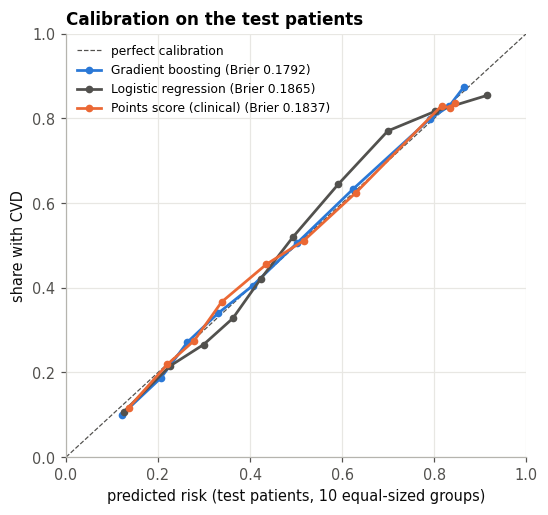

In [51]:
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss

fig, ax = plt.subplots(figsize=(5.4, 5.0))
ax.plot([0, 1], [0, 1], ls="--", lw=0.8, color=MUTED, label="perfect calibration")
for name, colour in [(chosen, NO_CVD), ("Logistic regression", MUTED), ("Points score (clinical)", CVD)]:
    observed, predicted = calibration_curve(y_test, test_scores[name], n_bins=10, strategy="quantile")
    brier = brier_score_loss(y_test, test_scores[name])
    ax.plot(predicted, observed, "-o", color=colour, lw=1.8, ms=4, label=f"{name} (Brier {brier:.4f})")
ax.set(xlabel="predicted risk (test patients, 10 equal-sized groups)", ylabel="share with CVD",
       title="Calibration on the test patients", xlim=(0, 1), ylim=(0, 1))
ax.legend(loc="upper left", fontsize=8)
fig.savefig(FIGURES / "fig13_calibration.png")
plt.show()

**Gradient boosting's risks can be read as risks, in this sample.** Its ten points lie close to the
diagonal: patients given about 20% have CVD about 20% of the time, and patients given 80% about 80% of
the time. It also has the lowest Brier score (0.179). Logistic regression bends around the diagonal:
it overstates the lower risks and understates those around 60-70%, the error of a straight line
forced through a curved relationship (Section 8.4). The clinical card's risks, read from the training
patients' rates at each total, are close to calibrated too (Brier 0.184), with a small excess of
observed cases around 35-45%. All of these risks hold for a population in which half the patients are
sick (Section 9.5).

### 9.4 How does the model do for different patients?

In [52]:
subgroups = subgroup_table(test, test_scores[chosen])
rng = np.random.default_rng(SEED)
y_arr, risk_arr, male = y_test.to_numpy(), np.asarray(test_scores[chosen]), test["male"].to_numpy()
sex_gaps = []
for _ in range(1000):
    i = rng.integers(0, len(y_arr), len(y_arr))
    t, r, m = y_arr[i], risk_arr[i], male[i]
    sex_gaps.append(roc_auc_score(t[m == 1], r[m == 1]) - roc_auc_score(t[m == 0], r[m == 0]))
lo, hi = np.percentile(sex_gaps, [2.5, 97.5])
print(f"AUC, men minus women: {subgroups.loc['men', 'AUC'] - subgroups.loc['women', 'AUC']:+.3f} "
      f"(95% CI {lo:+.3f} to {hi:+.3f})")
subgroups.style.format({"patients": "{:,}", "share with CVD": "{:.1%}", "mean predicted risk": "{:.1%}",
                        "AUC": "{:.3f}", "systolic alone AUC": "{:.3f}", "sensitivity": "{:.1%}",
                        "specificity": "{:.1%}"})

AUC, men minus women: +0.005 (95% CI -0.011 to +0.020)


,patients,share with CVD,mean predicted risk,AUC,AUC 95% CI,systolic alone AUC,sensitivity,specificity
group,,,,,,,,
women,"8,858",49.2%,48.7%,0.803,0.794-0.812,0.756,68.0%,78.6%
men,"4,864",49.9%,50.7%,0.808,0.796-0.819,0.752,70.4%,77.6%
age < 50,"4,361",36.8%,36.3%,0.835,0.822-0.847,0.796,59.0%,91.4%
age 50-59,"6,900",50.8%,51.6%,0.768,0.756-0.779,0.730,64.2%,77.7%
age 60+,"2,461",67.9%,66.5%,0.718,0.696-0.740,0.681,88.1%,34.7%
everyone,"13,722",49.4%,49.4%,0.804,0.797-0.811,0.754,68.9%,78.2%


- **Women and men are served similarly.** Their AUCs are 0.803 and 0.808; the difference (+0.005, 95%
  CI −0.011 to +0.020) is within the noise, and in both groups the mean predicted risk is within 1
  point of the observed share.
- **Discrimination is lower in older groups, for the model and for systolic pressure alone.** The
  model's AUC falls from 0.835
  under 50 to 0.768 at 50-59 and 0.718 at 60 and over, and systolic pressure alone falls the same way
  (0.796, 0.730, 0.681). So this reflects the information more than the model: blood pressure
  separates sick from healthy less well among older patients. AUCs of these groups are also not
  strictly comparable: the groups differ in case mix (37%, 51% and 68% have CVD), and within a narrow
  age band age itself no longer separates anyone, which lowers any model's AUC there.
- **The risks hold in every group on average.** The mean predicted risk is within 1.5 points of the
  observed share in each group (calibration-in-the-large; the full calibration curve of Section 9.3
  covers all patients). Because most patients over 60 are sick (68%), a calibrated model flags most of
  them at the 0.5 cut-off (88% sensitivity, 35% specificity), while under 50 it is the reverse (59%
  and 91%). That is the same cut-off applied to different risks, not a different rule for different
  ages; whether older patients should be referred at a different risk is a clinical question about
  costs, not a statistical one.

### 9.5 What the numbers mean outside this dataset

Half the patients in this dataset have CVD. In the population that attends a routine check-up the
share is much lower, and this changes what a positive prediction means. Sensitivity and specificity
describe the model; they are assumed here to carry over to a population with a similar mix of
patients, which is a simplification (a milder case mix would make sick patients harder to detect).
The **positive predictive value**, the chance that a flagged patient really has CVD, depends on how
common the disease is. These are point estimates:

In [53]:
m_acc = classification_metrics(y_test, test_scores[chosen], 0.5)
m_scr = classification_metrics(y_test, test_scores[chosen], cut_screen)
ppv = pd.DataFrame({f"{label} (sens {m['sensitivity']:.0%}, spec {m['specificity']:.0%})":
                    {f"{p:.0%}": ppv_at_prevalence(m["sensitivity"], m["specificity"], p)
                     for p in (0.5, 0.3, 0.2, 0.1, 0.05)}
                    for label, m in [("accuracy cut-off", m_acc), ("screening cut-off", m_scr)]})
ppv.index.name = "share of patients with CVD"
ppv.style.format("{:.0%}")

,"accuracy cut-off (sens 69%, spec 78%)","screening cut-off (sens 80%, spec 64%)"
share of patients with CVD,,
50%,76%,69%
30%,58%,49%
20%,44%,36%
10%,26%,20%
5%,14%,11%


In this dataset 76% of the patients the model flags really have CVD. In a check-up population where
one patient in five has CVD, the same model, with the same sensitivity and specificity, would be right
about only 44% of the patients it flags (36% at the screening cut-off). The model is still useful
there, because it concentrates the disease: 44% is more than twice the 20% base rate. But its verdict
has to be read as "worth a closer look", not as a diagnosis. And before its *risks* could be used in
such a population, it would have to be recalibrated to that population's prevalence.

## 10. Using the model

The project's goal was a model that checks a patient for cardiovascular disease. The code below
turns the chosen model into that check. It saves the model with its two cut-offs and the clinical
scorecard to `outputs/model.joblib`. It also checks a new examination with the same plausibility
rules as the data, and only for ages the model was trained on (30 to 65), so an impossible or
out-of-range input is rejected instead of scored. It then reports the risk, the verdict and the
points.

In [54]:
MODEL_FILE = OUTPUTS / "model.joblib"
# The setting Section 7 selected for gradient boosting by cross-validation, for building the model
# without repeating the search (Section 10 prints the setting the search selected, which should match)
FINAL_PARAMS = {"learning_rate": 0.01, "max_leaf_nodes": 15, "min_samples_leaf": 50}
SCREENING_SENSITIVITY = 0.80
AGE_RANGE = (30, 65)   # years: the ages the model was trained on


def final_estimator():
    from sklearn.ensemble import HistGradientBoostingClassifier
    return HistGradientBoostingClassifier(max_iter=1000, early_stopping=True, random_state=SEED, **FINAL_PARAMS)


def build_final(train: pd.DataFrame, model=None) -> dict:
    """Everything needed to assess a new patient: the fitted model, the two cut-offs and the scorecard."""
    model = model if model is not None else final_estimator().fit(train[FEATURES], train[TARGET])
    oof = out_of_fold(model, train)
    return {"model": model, "accuracy_cutoff": 0.5,
            "screening_cutoff": screening_threshold(train[TARGET], oof, SCREENING_SENSITIVITY),
            "points": PointsScore(factors=CLINICAL_FACTORS).fit(train, train[TARGET]), "features": FEATURES}


def save_final(bundle: dict, path: Path | str = MODEL_FILE) -> Path:
    """Save the bundle. The scorecard is stored as plain numbers (PointsScore.to_dict), so the file
    loads in any program that has this code, not only in the one that created it."""
    import joblib
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    joblib.dump({**bundle, "points": bundle["points"].to_dict()}, path)
    return path


def load_final(path: Path | str = MODEL_FILE) -> dict:
    import joblib
    if not Path(path).exists():
        raise FileNotFoundError(f"{path} not found: fit and save the final model first (build_final, save_final)")
    bundle = joblib.load(path)
    return {**bundle, "points": PointsScore.from_dict(bundle["points"])}


def patient(age: float, sex: str, height: float, weight: float, systolic: float, diastolic: float,
            cholesterol: int = 1, glucose: int = 1, smoke: int = 0, alcohol: int = 0, active: int = 1) -> pd.DataFrame:
    """One patient's examination as a model-ready row, after the same plausibility checks as the data.

    age in years; sex 'female' or 'male'; height cm; weight kg; blood pressure mmHg; cholesterol and
    glucose 1 normal, 2 above normal, 3 well above normal; smoke, alcohol, active 0 or 1.
    """
    if sex not in ("female", "male"):
        raise ValueError("sex must be 'female' or 'male'")
    for name, value in [("age", age), ("height", height), ("weight", weight), ("systolic", systolic),
                        ("diastolic", diastolic)]:
        if isinstance(value, bool) or not isinstance(value, (int, float)) or not math.isfinite(value):
            raise ValueError(f"{name} must be a number, not {value!r}")
    if not AGE_RANGE[0] <= age <= AGE_RANGE[1]:
        raise ValueError(f"age {age:g} is outside the {AGE_RANGE[0]}-{AGE_RANGE[1]} years the model was trained on")
    for name, value, allowed in [("cholesterol", cholesterol, (1, 2, 3)), ("glucose", glucose, (1, 2, 3)),
                                 ("smoke", smoke, (0, 1)), ("alcohol", alcohol, (0, 1)), ("active", active, (0, 1))]:
        if value not in allowed:
            raise ValueError(f"{name} must be one of {allowed}, not {value!r}")
    raw = pd.DataFrame([{"id": 0, "age": age * 365.25, "gender": 2 if sex == "male" else 1, "height": height,
                         "weight": weight, "ap_hi": systolic, "ap_lo": diastolic, "cholesterol": cholesterol,
                         "gluc": glucose, "smoke": smoke, "alco": alcohol, "active": active, TARGET: 0}])
    failed = audit(raw).iloc[0]
    if failed.any():
        raise ValueError("implausible examination values: " + ", ".join(failed.index[failed]))
    return add_features(prepare(raw))


def assess(bundle: dict, row: pd.DataFrame) -> dict:
    """Predicted risk, the verdict at both cut-offs, and the scorecard's points for one patient."""
    risk = float(bundle["model"].predict_proba(row[bundle["features"]])[:, 1][0])
    points = bundle["points"]
    design = points._design(row)[points.points_.index].iloc[0]
    earned = points.points_[design == 1]
    readable = {}
    for column, value in earned.items():
        factor = next(f for f in points.factors if column.startswith(f + "_"))
        readable[f"{POINTS_LABELS[factor]}: {column[len(factor) + 1:]}"] = int(value)
    return {"risk": risk,
            "verdict": "cardiovascular disease likely" if risk >= bundle["accuracy_cutoff"] else "cardiovascular disease unlikely",
            "screening": "refer for examination" if risk >= bundle["screening_cutoff"] else "no referral",
            "screening_cutoff": bundle["screening_cutoff"],
            "points": int(earned.sum()), "points_risk": float(points.predict_proba(row)[0]),
            "points_breakdown": {k: v for k, v in readable.items() if v != 0}}

In [55]:
print("selected setting:", {k: v for k, v in final.get_params().items() if k in FINAL_PARAMS})
bundle = build_final(train, model=final)
print("saved:", save_final(bundle).relative_to(ROOT))
print(f"screening cut-off: {bundle['screening_cutoff']:.3f}")

selected setting: {'learning_rate': 0.01, 'max_leaf_nodes': 15, 'min_samples_leaf': 50}


saved: outputs/model.joblib
screening cut-off: 0.382


Three invented examination records show the output:

In [56]:
examples = {
    "62-year-old man, 165/100 mmHg, BMI 33, cholesterol well above normal":
        dict(age=62, sex="male", height=172, weight=98, systolic=165, diastolic=100, cholesterol=3),
    "44-year-old woman, 115/75 mmHg, BMI 22, all results normal":
        dict(age=44, sex="female", height=165, weight=60, systolic=115, diastolic=75),
    "55-year-old woman, 130/85 mmHg, BMI 27, cholesterol above normal":
        dict(age=55, sex="female", height=160, weight=69, systolic=130, diastolic=85, cholesterol=2),
}
rows = []
for label, values in examples.items():
    r = assess(bundle, patient(**values))
    rows.append({"patient": label, "predicted risk": r["risk"], "verdict": r["verdict"],
                 "screening": r["screening"], "points": r["points"], "risk from points": r["points_risk"]})
pd.DataFrame(rows).set_index("patient").style.format({"predicted risk": "{:.0%}", "risk from points": "{:.0%}"})

,predicted risk,verdict,screening,points,risk from points
patient,,,,,
"62-year-old man, 165/100 mmHg, BMI 33, cholesterol well above normal",87%,cardiovascular disease likely,refer for examination,50,85%
"44-year-old woman, 115/75 mmHg, BMI 22, all results normal",14%,cardiovascular disease unlikely,no referral,0,8%
"55-year-old woman, 130/85 mmHg, BMI 27, cholesterol above normal",59%,cardiovascular disease likely,refer for examination,26,68%


The three invented patients get the answers a clinician would expect. The 62-year-old man with
stage 2 hypertension, obesity and high cholesterol is at 87% (the clinical card gives him 50 points,
85%). The young woman with normal results is at 14% (0 points, 8%). The 55-year-old woman in between
is at 59% (26 points, 68%), so she is referred at either cut-off. The card and the model rank the
three patients in the same order.

In [57]:
for values in [dict(age=50, sex="male", height=175, weight=80, systolic=1400, diastolic=90),
               dict(age=80, sex="female", height=160, weight=60, systolic=120, diastolic=80)]:
    try:
        patient(**values)
    except ValueError as e:
        print("rejected:", e)

rejected: implausible examination values: ap_hi out of range
rejected: age 80 is outside the 30-65 years the model was trained on


The saved file holds the model, the two cut-offs and the scorecard (the scorecard as plain
numbers). With this notebook's code loaded, `assess(load_final(), patient(...))` gives the same
answer in a later session, without retraining.

## 11. Conclusion

**Objective met.** A gradient-boosting model detects cardiovascular disease from the eleven values of
a routine examination. On 13,722 patients it never saw, it reaches an AUC of 0.804 (95% CI
0.797-0.811) and 73.6% accuracy (72.9-74.4%). Its risks are well calibrated in this sample, and it
performs similarly for women and men. Section 10 packages it as a check of a new examination that
rejects impossible values and returns a risk, a verdict and a points breakdown.

**Q1. What machine learning adds over what a doctor already has: something real, but small.**

- **Over the guideline rule.** The model beats systolic pressure ≥ 130 mmHg by 2.3 points of accuracy
  (95% CI 1.8 to 2.9). At an operating point matched to the rule's specificity on training data, it
  detects 274 more of the 6,785 diseased test patients (95% CI 220 to 332), with no clear difference
  in false alarms.
- **Between the models.** Gradient boosting, random forest and the neural network are within the
  cross-validation noise of each other and within 0.004 AUC on the test set; logistic regression is
  0.012 AUC behind.
- **The scorecard.** A four-factor paper score comes within 0.012 AUC and about one point of accuracy
  of the best model.
- **Why the gain is small.** The learning curves flatten, very different algorithms end up close
  together, and the searches are flat: the limit near 0.80 AUC (about 73% accuracy) seems to lie
  mainly in what the examination records, rather than in the algorithm or the amount of data.
- **The Framingham score.** As published, it ranks these patients worse than blood pressure alone,
  partly because of its sex and smoking weights. Refitted to these patients, it beats systolic
  pressure alone (AUC 0.780 against 0.754) but stays clearly below the models.

**Q2. Data handling can change the reported performance far more than the choice of algorithm.**

- **Cleaning.** Fewer than 2% of records nearly erase systolic pressure's correlation with the
  diagnosis (0.05, against 0.43 after cleaning) and cost logistic regression 0.017 AUC. Tree models
  barely notice the dirty data, and repairing the records is as good as dropping them. The removed
  records are mostly from sick patients; adding back the repairable ones changes the headline very
  little.
- **Leakage.** Two common evaluation mistakes turn the same data into reported accuracies of
  85-100%. Claims far above 74% on this dataset call for a close look at how they were evaluated.

**Q3. The predictions can be trusted, within limits.**

- **Calibration.** The risks are calibrated in this sample, and on average within every sex and age
  group.
- **What drives them.** Blood pressure, age and cholesterol dominate, in the direction medicine
  expects.
- **Limits.** Discrimination is lower among older patients, for the model and for systolic pressure
  alone. The lifestyle answers carry associations, possibly reverse-caused for smoking, that must not
  be read as effects.

### Limitations

1. **Detection, not prediction.** Diagnosis and features come from the same examination. The model
   recognises existing disease. It cannot forecast who will develop CVD.
2. **Unknown provenance and outcome definition.** The dataset's source and the exact meaning of
   "cardiovascular disease" are undocumented. If the label includes diagnosed hypertension, part of
   blood pressure's predictive power is circular.
3. **Treatment is not recorded.** Medication lowers blood pressure and cholesterol in diagnosed
   patients, and diagnosis may change habits. Both can weaken or reverse associations (Section 5.2),
   and neither can be corrected for here.
4. **A 50/50 sample.** Predictive values and absolute risks apply to this sample. Another population
   needs recalibration (Section 9.5).
5. **Records with entry errors are mostly from sick patients.** The main test set leaves them out;
   Section 9.1 reports how the model does on those that can be repaired.
6. **One dataset, one split, one fit per model.** All results come from one source and one
   train/test split, with no external validation. The confidence intervals cover the sampling of test
   patients, not the randomness of training. The search grids differ in size between models, and the
   report was revised after its test results had been seen (Section 2).
7. **Coarse measurements.** Cholesterol and glucose come in three categories, almost all blood
   pressures are rounded to 10 mmHg, and diabetes had to be approximated for the Framingham score.

The next step for this model would be validation on data from a known clinical source, with
recorded treatment and, ideally, outcomes followed over time. Those are what would turn a detector of
existing disease into a tool for prevention.

## References

1. World Health Organization. *Cardiovascular diseases (CVDs)*, fact sheet, updated 31 July 2025.
2. S. Ulianova. *Cardiovascular Disease dataset*. Kaggle, 2019.
3. P. K. Whelton et al. 2017 ACC/AHA guideline for the prevention, detection, evaluation, and
   management of high blood pressure in adults. *Hypertension*, 71(6):e13-e115, 2018.
4. R. B. D'Agostino Sr et al. General cardiovascular risk profile for use in primary care: the
   Framingham Heart Study. *Circulation*, 117(6):743-753, 2008.
5. R. S. Ramesh, R. T. S. Udupa, Monisha J and Kushi K. K. S. Cardiovascular disease prediction using
   machine learning: a comparative analysis. arXiv:2507.21898, 2025.
6. D. Y. Omkari and K. Shaik. An integrated two-layered voting (TLV) framework for coronary artery
   disease prediction using machine learning classifiers. *IEEE Access*, 12:56275-56290, 2024.
   doi:10.1109/ACCESS.2024.3389707. A correction was published (*IEEE Access*, 12:162564, 2024,
   doi:10.1109/ACCESS.2024.3490072); it could not be consulted here.
7. R. B. Z. Auvee et al. Cardiovascular diagnostic detection using multilayer perceptron approach.
   *Systems and Soft Computing*, 8:200490, 2026. doi:10.1016/j.sasc.2026.200490.
8. A. G. Shaper, G. Wannamethee and M. Walker. Alcohol and mortality in British men: explaining the
   U-shaped curve. *The Lancet*, 2(8623):1267-1273, 1988.
9. C. Rudin. Stop explaining black box machine learning models for high stakes decisions and use
   interpretable models instead. *Nature Machine Intelligence*, 1:206-215, 2019.
10. N. V. Chawla, K. W. Bowyer, L. O. Hall and W. P. Kegelmeyer. SMOTE: synthetic minority
    over-sampling technique. *Journal of Artificial Intelligence Research*, 16:321-357, 2002.
11. M. Eltawil et al. Comment on Iacobescu et al. "Evaluating binary classifiers for cardiovascular
    disease prediction: enhancing early diagnostic capabilities". *Journal of Cardiovascular
    Development and Disease*, 13(1):46, 2026. doi:10.3390/jcdd13010046.
12. F. Pedregosa et al. Scikit-learn: machine learning in Python. *Journal of Machine Learning
    Research*, 12:2825-2830, 2011.